# Modelo de PD de originación – María Isabel Aristizabal Alzate
Objetivo: construir y validar un modelo de probabilidad de incumplimiento
para solicitantes sin historial en buró, usando datos alternativos.

## 1. Carga de datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

RAW = Path("../data/raw")
pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")

In [2]:
sol_raw = pd.read_csv(RAW / "dataset_candidato.csv", sep=";", dtype=str, keep_default_na=False)
car_raw = pd.read_csv(RAW / "cartera_variable_respuesta_candidato.csv", dtype=str, keep_default_na=False)
print("Solicitudes:", sol_raw.shape, "| Cartera:", car_raw.shape)

Solicitudes: (4000, 19) | Cartera: (18169, 5)


In [3]:
sol_raw.head()

,application_id,application_date,age,sexo,monthly_income_declared,app_tenure_months,avg_monthly_topups,num_transactions_last_90d,pct_p2p_transfers,device_price_tier,has_bureau_record,bureau_score,utility_payment_ontime_rate,telco_payment_ontime_rate,digital_engagement_score,monto_bono_referidos,requested_amount,product_type,disbursed_flag
0,CAND-02052,1/01/24,22,M,1149897.0,7,14838.0,2,0.712,3,FALSE,,0.524,0.728,52.7,0.0,1160359.0,compra_cartera,TRUE
1,CAND-00752,1/01/24,33,M,616023.0,11,51171.0,3,0.288,3,FALSE,,0.822,0.938,50.3,0.0,273514.0,libre_inversion,TRUE
2,CAND-00542,1/01/24,43,M,3064570.0,7,31961.0,6,0.36,1,FALSE,,0.547,0.915,81.2,0.0,283447.0,libre_inversion,TRUE
3,CAND-01204,1/01/24,34,H,1817355.0,7,43710.0,3,0.515,2,FALSE,,0.501,0.922,59.6,0.0,741165.0,libre_inversion,TRUE
4,CAND-02825,1/01/24,30,M,879261.0,5,37064.0,2,0.544,4,TRUE,530.0,0.697,0.738,19.5,0.0,167681.0,avance_efectivo,TRUE


In [4]:
car_raw.head()

,application_id,fecha_apertura,fecha_corte,altura_mora,saldo_capital
0,CAND-00001,2024-03-20,2024-04-19,0,428989.0
1,CAND-00001,2024-03-20,2024-05-19,0,386445.0
2,CAND-00001,2024-03-20,2024-06-18,0,347446.0
3,CAND-00001,2024-03-20,2024-07-18,0,314018.0
4,CAND-00002,2024-08-22,2024-09-21,0,784934.0


En la siguiente celda se revisa, para cada variable que debería ser numérica:
- cuántos valores **no se pueden convertir a número** (indicador de datos corruptos), y
- cuántos valores **nulos** tiene.  
Primero se reemplazan los textos vacíos por nulos reales (`NaN`).

In [5]:
sol = sol_raw.replace("", np.nan)
num_cols = ["age","monthly_income_declared","app_tenure_months","avg_monthly_topups",
            "num_transactions_last_90d","pct_p2p_transfers","device_price_tier","bureau_score",
            "utility_payment_ontime_rate","telco_payment_ontime_rate","digital_engagement_score",
            "monto_bono_referidos","requested_amount"]
pd.DataFrame({
    "no_numericos": {c: int((pd.to_numeric(sol[c], errors="coerce").isna() & sol[c].notna()).sum()) for c in num_cols},
    "nulos": sol[num_cols].isna().sum(),
})

,no_numericos,nulos
age,0,0
monthly_income_declared,49,0
app_tenure_months,0,0
avg_monthly_topups,0,0
num_transactions_last_90d,0,0
pct_p2p_transfers,0,0
device_price_tier,0,0
bureau_score,0,2191
utility_payment_ontime_rate,0,255
telco_payment_ontime_rate,0,241


En la siguiente celda se verifica que `application_id` sea una llave única
y se revisan las frecuencias de las variables categóricas y binarias
para detectar niveles inesperados.

In [6]:
print("IDs duplicados:", sol["application_id"].duplicated().sum())
for c in ["sexo", "product_type", "has_bureau_record", "disbursed_flag", "device_price_tier"]:
    print(c, sol[c].value_counts(dropna=False).to_dict())

IDs duplicados: 0
sexo {'H': 1984, 'M': 1853, 'NB': 163}
product_type {'libre_inversion': 2192, 'avance_efectivo': 1004, 'compra_cartera': 804}
has_bureau_record {'FALSE': 2191, 'TRUE': 1809}
disbursed_flag {'TRUE': 3930, 'FALSE': 70}
device_price_tier {'1': 1236, '2': 1087, '3': 848, '4': 554, '5': 275}


En la siguiente celda vemos los registros de `monthly_income_declared` que no se pudieron convertir a número, para entender por qué paso esto.

In [7]:
sol.loc[pd.to_numeric(sol["monthly_income_declared"], errors="coerce").isna(),
        ["application_id", "monthly_income_declared"]].head(10)

,application_id,monthly_income_declared
163,CAND-02580,13.760.566.878.899.200
178,CAND-00518,13.777.722.536.049.300
243,CAND-01908,7.071.149.473.249.980
296,CAND-02728,14.990.568.150.977.100
316,CAND-00750,24.123.345.785.788.900
469,CAND-01013,1.924.125.405.490.580
706,CAND-00506,2.686.018.256.156.650
744,CAND-00272,10.393.513.001.866.500
859,CAND-01997,961.705.411.118.913
930,CAND-02771,9.475.369.019.294.410


### Hallazgos de la carga inicial

- **Formato de archivos:** el dataset de solicitudes viene separado por `;` y el de cartera
  por `,`. Se leyeron ambos como texto (`dtype=str`) para no imponer tipos y poder
  detectar anomalías de formato antes de convertir.
- **Tamaño:** 4.000 solicitudes (19 variables) y 18.169 registros de cartera
  (panel mensual: varios cortes por crédito).
- **Llave:** `application_id` es única en solicitudes (0 duplicados).
- **Ingreso con formato corrupto:** 49 registros de `monthly_income_declared` (1,2 %) no
  son numéricos, p. ej. `13.760.566.878.899.200`. Parece un número decimal exportado con
  separadores de miles locales donde se perdió la coma decimal
  (≈ 1.376.056,68). No se eliminan: en el siguiente paso se intenta recuperarlos.
- **Nulos:**
  - `bureau_score` tiene 2.191 nulos, exactamente el mismo número de solicitudes con
    `has_bureau_record = FALSE` → es un **nulo estructural** (clientes thin-file),
    no un dato faltante.
  - `utility_payment_ontime_rate` (255) y `telco_payment_ontime_rate` (241) tienen
    ~6 % de nulos → faltantes reales de datos alternativos.
- **Desembolso:** 70 solicitudes (1,75 %) no se desembolsaron; no deberían tener
  registro en cartera ni desempeño observable.
- **Categóricas:** `sexo` (H 1.984, M 1.853, NB 163), `product_type` con 3 niveles,
  `device_price_tier` de 1 a 5. Sin categorías inesperadas.

## 2. Calidad de datos – solicitudes

### 2.1 Recuperar el ingreso corrupto.
En la siguiente celda vemos los ingresos con formato corrupto.  

**Regla**: se eliminarán los puntos y se toma el prefijo de dígitos cuyo valor cae dentro del rango de ingresos válidos observados (mínimo y máximo de los registros normales).
Si existe exactamente un candidato, se usa; si hay ambigüedad, se deja nulo.
Se crea `flag_income_recovered` para trazabilidad, y se compara la distribución
de los ingresos recuperados contra la de los válidos para confirmar que la regla
produce valores coherentes.

In [8]:
ok_inc = pd.to_numeric(sol["monthly_income_declared"], errors="coerce")
INC_MIN, INC_MAX = ok_inc.min(), ok_inc.max() * 1.01
print(f"Rango de ingresos válidos: {INC_MIN:,.0f} – {ok_inc.max():,.0f}")

def recuperar_ingreso(valor):
    v = pd.to_numeric(valor, errors="coerce")
    if pd.notna(v):
        return v, 0
    digitos = str(valor).replace(".", "")
    candidatos = [int(digitos[:L]) for L in range(4, len(digitos))
                  if INC_MIN <= int(digitos[:L]) <= INC_MAX]
    return (float(candidatos[0]), 1) if len(candidatos) == 1 else (np.nan, 1)

tmp = sol["monthly_income_declared"].map(recuperar_ingreso)
sol["income"] = tmp.map(lambda t: t[0])
sol["flag_income_recovered"] = tmp.map(lambda t: t[1])

rec = sol[sol.flag_income_recovered == 1]
print("Recuperados:", rec["income"].notna().sum(), "de", len(rec))
display(rec[["monthly_income_declared", "income"]].head())
pd.concat([ok_inc.describe().rename("validos"), rec["income"].describe().rename("recuperados")], axis=1)

Rango de ingresos válidos: 300,000 – 5,067,733
Recuperados: 49 de 49


,monthly_income_declared,income
163,13.760.566.878.899.200,1376056.0
178,13.777.722.536.049.300,1377772.0
243,7.071.149.473.249.980,707114.0
296,14.990.568.150.977.100,1499056.0
316,24.123.345.785.788.900,2412334.0


,validos,recuperados
count,3.951000e+03,4.900000e+01
mean,1.333014e+06,1.395187e+06
std,6.270366e+05,5.967551e+05
min,3.000000e+05,5.208970e+05
25%,8.899220e+05,9.617050e+05
50%,1.201639e+06,1.218382e+06
75%,1.624324e+06,1.718219e+06
max,5.067733e+06,2.924354e+06


### 2.2 Convertir tipos y fechas
En la siguiente celda se convierten las variables a su tipo correcto: numéricas a número, banderas `TRUE/FALSE` a booleano y `application_date` a fecha con formato  `d/mm/yy`. Se verifica que no queden fechas sin convertir y se revisa el número de solicitudes por mes.

In [9]:
for c in num_cols:
    if c != "monthly_income_declared":
        sol[c] = pd.to_numeric(sol[c])
for c in ["has_bureau_record", "disbursed_flag"]:
    sol[c] = sol[c].astype(str).str.upper().eq("TRUE")   # funciona sea texto o booleano

if sol["application_date"].dtype == object or str(sol["application_date"].dtype).startswith("str"):
    print("Longitudes de application_date:", sol["application_date"].str.len().value_counts().to_dict())
    sol["application_date"] = pd.to_datetime(sol["application_date"], format="%d/%m/%y", errors="coerce")
print("Fechas no parseables:", sol["application_date"].isna().sum(),
      "| rango:", sol["application_date"].min().date(), "→", sol["application_date"].max().date())
print(sol[["has_bureau_record", "disbursed_flag"]].value_counts().to_dict())
sol["application_date"].dt.to_period("M").value_counts().sort_index()

Longitudes de application_date: {8: 2857, 7: 1143}
Fechas no parseables: 0 | rango: 2024-01-01 → 2024-12-31
{(False, True): 2152, (True, True): 1778, (False, False): 39, (True, False): 31}


application_date
2024-01    343
2024-02    339
2024-03    335
2024-04    352
2024-05    333
2024-06    359
2024-07    302
2024-08    337
2024-09    300
2024-10    346
2024-11    324
2024-12    330
Freq: M, Name: count, dtype: int64

### 2.3 Reglas de consistencia de negocio
En la siguiente celda se validan reglas de consistencia de negocio:
- que el score de buró sea nulo sólo cuando no hay registro en buró,
- que esté en un rango válido,
- que las tasas estén entre 0 y 1,
- que los scores y niveles estén en su escala,
- que la edad sea de un adulto
- y que montos y conteos no sean negativos.

In [10]:
reglas = {
    "bureau_score nulo ⇔ sin buró": ((sol.bureau_score.isna()) == (~sol.has_bureau_record)).all(),
    "bureau_score en [300, 900]": sol.bureau_score.dropna().between(300, 900).all(),
    "tasas en [0, 1]": all(sol[c].dropna().between(0, 1).all() for c in
                          ["utility_payment_ontime_rate", "telco_payment_ontime_rate", "pct_p2p_transfers"]),
    "engagement en [0, 100]": sol.digital_engagement_score.between(0, 100).all(),
    "device_price_tier en 1..5": sol.device_price_tier.isin(range(1, 6)).all(),
    "edad en [18, 100]": sol.age.between(18, 100).all(),
    "montos y conteos ≥ 0": (sol[["avg_monthly_topups", "num_transactions_last_90d", "monto_bono_referidos",
                                  "requested_amount", "app_tenure_months"]] >= 0).all().all(),
}
pd.Series(reglas, name="cumple").to_frame()

,cumple
bureau_score nulo ⇔ sin buró,True
"bureau_score en [300, 900]",True
"tasas en [0, 1]",True
"engagement en [0, 100]",True
device_price_tier en 1..5,True
"edad en [18, 100]",True
montos y conteos ≥ 0,True


### Hallazgos – calidad de datos de solicitudes

- **Ingresos recuperados:** los 49 ingresos corruptos se recuperaron sin ambigüedad
  (un único candidato en el rango válido de 300.000 – 5.067.733). La distribución de
  los recuperados (mediana ≈ 1,22 M) es muy similar a la de los válidos
  (mediana ≈ 1,20 M), lo que respalda la regla. Se conserva `flag_income_recovered`
  para trazabilidad.
- **Fechas de solicitud:** todas se convirtieron (0 errores). Van del 01-01-2024 al
  31-12-2024, con un volumen estable de ≈ 300–360 solicitudes por mes, sin meses
  faltantes ni picos atípicos.
- **Reglas de negocio:** se cumplen todas. En particular, `bureau_score` es nulo
  **si y sólo si** el cliente no tiene registro en buró, confirmando que es un nulo
  estructural y no un dato faltante que deba imputarse.
- **Nota de reproducibilidad:** la conversión de tipos se escribió de forma que
  pueda re-ejecutarse sin alterar los datos (idempotente).

### 2.4 Atípicos y anomalías de distribución
En la siguiente celda se construye un resumen estadístico de las variables numéricas
con percentiles extremos (1 %, 5 %, 95 %, 99 %). Además se calcula, para cada variable,
el porcentaje de valores atípicos según el criterio de 3 rangos intercuartílicos
(más conservador que el 1,5·IQR clásico, para marcar sólo extremos reales) y la
asimetría (*skew*) para identificar distribuciones con colas largas.

In [11]:
vars_num = ["age", "income", "app_tenure_months", "avg_monthly_topups", "num_transactions_last_90d",
            "pct_p2p_transfers", "bureau_score", "utility_payment_ontime_rate", "telco_payment_ontime_rate",
            "digital_engagement_score", "monto_bono_referidos", "requested_amount"]

desc = sol[vars_num].describe(percentiles=[.01, .05, .5, .95, .99]).T
atipicos = {}
for c in vars_num:
    s = sol[c].dropna()
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    atipicos[c] = ((s < q1 - 3 * iqr) | (s > q3 + 3 * iqr)).mean()
desc["pct_atipicos_3IQR"] = pd.Series(atipicos)
desc["skew"] = sol[vars_num].skew()
desc.round(3)

,count,mean,std,min,1%,5%,50%,95%,99%,max,pct_atipicos_3IQR,skew
age,4000.0,34.834,9.668,18.000,18.000,18.000,35.000,51.000,58.000,65.000,0.000,0.192
income,4000.0,1333775.318,626640.661,300000.000,436530.500,568595.050,1202313.000,2537853.350,3424989.750,5067733.000,0.005,1.368
app_tenure_months,4000.0,13.546,12.765,1.000,1.000,1.000,10.000,40.000,60.000,60.000,0.000,1.499
avg_monthly_topups,4000.0,49658.367,35505.372,818.000,3843.670,9354.500,41322.500,118011.900,169245.000,321154.000,0.005,1.558
num_transactions_last_90d,4000.0,6.828,6.892,0.000,0.000,0.000,5.000,21.000,30.010,49.000,0.004,1.618
pct_p2p_transfers,4000.0,0.397,0.199,0.006,0.041,0.097,0.384,0.750,0.852,0.969,0.000,0.306
bureau_score,1809.0,652.796,83.521,386.000,453.160,512.400,652.000,790.600,845.000,900.000,0.000,-0.029
utility_payment_ontime_rate,3745.0,0.730,0.148,0.165,0.332,0.456,0.750,0.935,0.970,0.998,0.000,-0.640
telco_payment_ontime_rate,3759.0,0.731,0.147,0.144,0.339,0.466,0.751,0.933,0.970,0.999,0.000,-0.644
digital_engagement_score,4000.0,50.246,19.615,0.000,3.197,17.700,50.250,83.000,96.600,100.000,0.000,-0.005


En la siguiente celda se grafica el histograma de cada variable numérica para
revisar visualmente la forma de las distribuciones, concentraciones anómalas
de valores y colas largas.

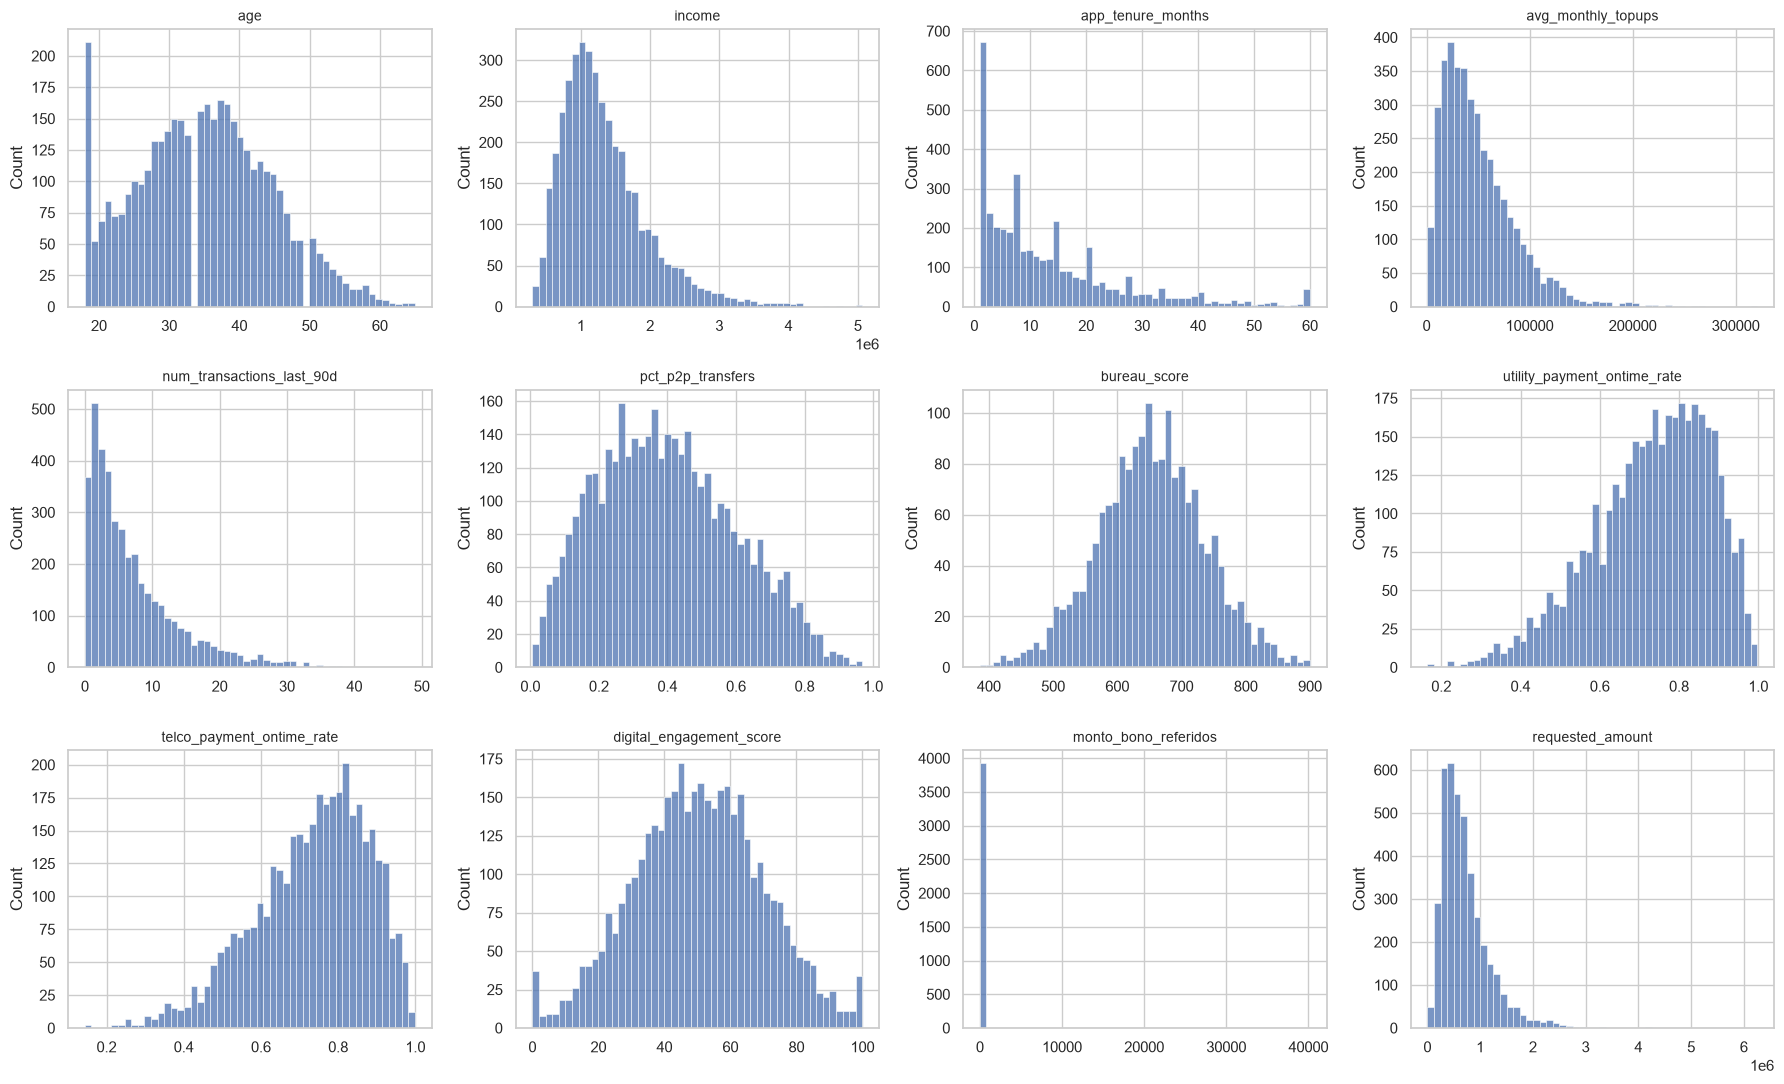

In [12]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, c in zip(axes.ravel(), vars_num):
    sns.histplot(sol[c].dropna(), bins=50, ax=ax, color="#4C72B0")
    ax.set_title(c, fontsize=10)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

En la siguiente celda se analiza en detalle la distribución de la edad, para verificar
si la acumulación observada en 18 años es natural o anómala comparándola con la
frecuencia de las edades vecinas (19 a 22 años).

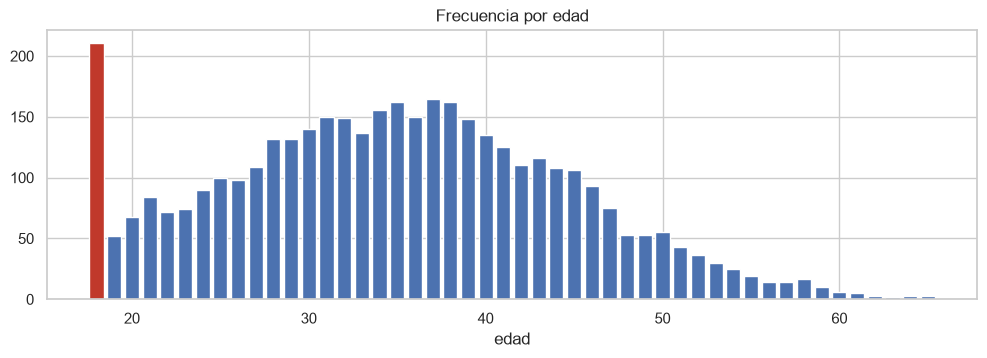

n(edad = 18): 211 | promedio edades 19–22: 69.0


In [13]:
conteo_edad = sol["age"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(conteo_edad.index, conteo_edad.values,
       color=["#C0392B" if a == 18 else "#4C72B0" for a in conteo_edad.index])
ax.set_title("Frecuencia por edad")
ax.set_xlabel("edad")
plt.show()
print("n(edad = 18):", conteo_edad[18], "| promedio edades 19–22:", round(conteo_edad.loc[19:22].mean(), 1))

En la siguiente celda se revisan los montos solicitados más pequeños, ya que el mínimo
(≈ 500) está muy por debajo del percentil 1 (≈ 107.000). Se busca identificar si se trata
de un grupo separado del resto de la distribución (posible error de unidades).

In [14]:
print("Solicitudes con monto < 5.000:", (sol["requested_amount"] < 5000).sum())
print("Solicitudes con monto entre 5.000 y 100.000:", sol["requested_amount"].between(5000, 100000).sum())
sol.nsmallest(30, "requested_amount")[["application_id", "requested_amount", "product_type", "income"]]

Solicitudes con monto < 5.000: 24
Solicitudes con monto entre 5.000 y 100.000: 12


,application_id,requested_amount,product_type,income
3425,CAND-03606,518.0,avance_efectivo,559211.0
2613,CAND-02466,543.0,avance_efectivo,703496.0
2748,CAND-00953,638.0,libre_inversion,2059785.0
3917,CAND-03006,639.0,compra_cartera,1646239.0
1480,CAND-02813,663.0,compra_cartera,627877.0
821,CAND-01049,678.0,compra_cartera,2268891.0
1888,CAND-01867,760.0,compra_cartera,707949.0
3272,CAND-03742,810.0,avance_efectivo,1093383.0
2677,CAND-00853,829.0,avance_efectivo,1569160.0
2271,CAND-00476,899.0,compra_cartera,2286058.0


En la siguiente celda se revisa `monto_bono_referidos`: proporción de ceros y
distribución de los valores positivos, para evaluar si la variable tiene variabilidad
suficiente para ser útil.

In [15]:
print(f"% de ceros: {(sol['monto_bono_referidos'] == 0).mean():.1%}")
sol.loc[sol["monto_bono_referidos"] > 0, "monto_bono_referidos"].describe()

% de ceros: 98.0%


count       78.000000
mean     16680.743590
std       8248.501462
min       5297.000000
25%      10816.250000
50%      15174.500000
75%      19746.250000
max      40189.000000
Name: monto_bono_referidos, dtype: float64

### Hallazgos – atípicos y distribuciones

- **Valores atípicos (3·IQR):** son escasos (< 1 % en todas las variables, salvo
  `monto_bono_referidos`). Las variables de monto y actividad (`income`,
  `avg_monthly_topups`, `num_transactions_last_90d`, `requested_amount`) tienen
  asimetría positiva (colas largas a la derecha), propia de variables monetarias.
  **No se eliminan ni recortan**: el modelo usará binning (WoE), que agrupa los
  extremos en el último rango y es robusto a colas.
- **Edad = 18 anómala:** 211 solicitantes tienen exactamente 18 años, más de 3 veces
  el promedio de las edades 19–22 (69). Es un patrón típico de *clipping* (edades
  menores o inválidas truncadas a 18) o de valor por defecto en el formulario.
  Se marcará con un indicador (`flag_age_18`).
- **Antigüedad en la app:** acumulación en 1 mes (clientes nuevos) y un pico en
  60 meses, que sugiere un **tope** de la variable (antigüedades mayores registradas
  como 60).
- **Engagement digital:** masas en 0 y en 100, extremos de la escala → valores
  truncados a los límites del score.
- **Montos solicitados en miles:** 24 solicitudes tienen montos entre 518 y 1.984,
  separadas del resto por un salto grande (el siguiente valor es 100.000, el
  mínimo del producto). Hipótesis: **capturados en miles**. Se valida en la
  sección de cartera contra el saldo de capital del primer corte.
- **`monto_bono_referidos`:** 98 % de ceros (sólo 78 casos con bono, entre 5 y 40 mil).
  Variable casi constante; se evaluará su poder predictivo, pero probablemente
  no aporte.
- **Datos alternativos** (utility y telco): asimetría negativa, la mayoría paga a
  tiempo; sin atípicos.

## 3. Calidad de datos – cartera

### 3.1 Formatos de fecha
En la siguiente celda se revisa el formato de las fechas del panel de cartera.
Se cuenta cuántas `fecha_apertura` vienen en formato `YYYY-MM-DD` y cuántas en otro
formato, y luego se convierte cada grupo con su patrón explícito: si se usara
inferencia automática, una fecha `DD-MM-YYYY` con día ≤ 12 podría interpretarse
como mes en silencio.

In [16]:
car = car_raw.copy()
iso = car["fecha_apertura"].str.match(r"^\d{4}-\d{2}-\d{2}$")
dmy = car["fecha_apertura"].str.match(r"^\d{2}-\d{2}-\d{4}$")
print(f"fecha_apertura → YYYY-MM-DD: {iso.sum():,} | DD-MM-YYYY: {dmy.sum():,} | otros: {(~iso & ~dmy).sum()}")
print("fecha_corte toda en YYYY-MM-DD:", car["fecha_corte"].str.match(r"^\d{4}-\d{2}-\d{2}$").all())

car["fecha_apertura"] = pd.to_datetime(car["fecha_apertura"].where(iso), format="%Y-%m-%d").fillna(
                        pd.to_datetime(car["fecha_apertura"].where(dmy), format="%d-%m-%Y"))
car["fecha_corte"] = pd.to_datetime(car["fecha_corte"], format="%Y-%m-%d")
car["altura_mora"] = car["altura_mora"].astype(int)
car["saldo_capital"] = car["saldo_capital"].astype(float)

print("Nulos tras convertir:", car[["fecha_apertura", "fecha_corte"]].isna().sum().to_dict())
print("Una sola fecha de apertura por crédito:", (car.groupby("application_id")["fecha_apertura"].nunique() == 1).all())
print("Apertura:", car.fecha_apertura.min().date(), "→", car.fecha_apertura.max().date(),
      "| Corte:", car.fecha_corte.min().date(), "→", car.fecha_corte.max().date())

fecha_apertura → YYYY-MM-DD: 18,087 | DD-MM-YYYY: 82 | otros: 0
fecha_corte toda en YYYY-MM-DD: True
Nulos tras convertir: {'fecha_apertura': 0, 'fecha_corte': 0}
Una sola fecha de apertura por crédito: True
Apertura: 2024-01-04 → 2025-01-29 | Corte: 2024-02-03 → 2025-07-26


### 3.2 Integridad referencial entre datasets
En la siguiente celda se valida la integridad referencial entre los dos datasets:
créditos de cartera sin solicitud, solicitudes no desembolsadas que sí tengan cartera
(no debería ocurrir) y solicitudes desembolsadas sin cartera.

In [17]:
ids_sol, ids_car = set(sol.application_id), set(car.application_id)
no_desemb = set(sol.loc[~sol.disbursed_flag, "application_id"])
desemb = set(sol.loc[sol.disbursed_flag, "application_id"])
huerfanos = sorted(ids_car - ids_sol)

display(pd.Series({
    "IDs únicos en cartera": len(ids_car),
    "En cartera sin solicitud (huérfanos)": len(huerfanos),
    "No desembolsadas con cartera": len(no_desemb & ids_car),
    "Desembolsadas sin cartera": len(desemb - ids_car),
}).to_frame("n"))
print("Ejemplos de huérfanos:", huerfanos[:5])

,n
IDs únicos en cartera,4052
En cartera sin solicitud (huérfanos),122
No desembolsadas con cartera,0
Desembolsadas sin cartera,0


Ejemplos de huérfanos: ['CAND-PH0001', 'CAND-PH0002', 'CAND-PH0003', 'CAND-PH0004', 'CAND-PH0005']


### 3.3 Estructura del panel: cortes, MOB y consistencia temporal
En la siguiente celda se revisa la estructura del panel: se ordena cada crédito por fecha
de corte y se numera cada corte (MOB, *month on book*). Se verifica que no haya cortes
duplicados ni anteriores a la apertura, cuántos días hay entre apertura y cada corte,
cuántos cortes tiene cada crédito, si el saldo aumenta en algún momento (no esperado
en un crédito que amortiza) y cuántos días pasan entre la solicitud y el desembolso.

In [18]:
car = car.sort_values(["application_id", "fecha_corte"]).reset_index(drop=True)
car["mob"] = car.groupby("application_id").cumcount() + 1
car["dias_desde_apertura"] = (car.fecha_corte - car.fecha_apertura).dt.days

print("Duplicados (id, corte):", car.duplicated(["application_id", "fecha_corte"]).sum())
print("Cortes en o antes de la apertura:", (car.fecha_corte <= car.fecha_apertura).sum())
display(car.groupby("mob")["dias_desde_apertura"].agg(["count", "min", "max"]).T)
print("Cortes por crédito:", car.groupby("application_id")["mob"].max().value_counts().sort_index().to_dict())
print("Cortes con aumento de saldo:", (car.groupby("application_id")["saldo_capital"].diff() > 0).sum())

lag = sol.merge(car.groupby("application_id").fecha_apertura.first().reset_index(), on="application_id")
lag["dias"] = (lag.fecha_apertura - lag.application_date).dt.days
print("Días solicitud → desembolso:", lag.dias.describe()[["min", "50%", "max"]].to_dict(),
      "| desembolso antes de solicitud:", (lag.dias < 0).sum())

Duplicados (id, corte): 0
Cortes en o antes de la apertura: 0


mob,1,2,3,4,5,6
count,4052,4052,4052,3031,2000,982
min,30,60,90,120,150,180
max,30,60,90,120,150,180


Cortes por crédito: {3: 1021, 4: 1031, 5: 1018, 6: 982}
Cortes con aumento de saldo: 0
Días solicitud → desembolso: {'min': 0.0, '50%': 15.0, 'max': 30.0} | desembolso antes de solicitud: 0


### 3.4 Número de cortes por cosecha
En la siguiente celda se cruza el mes de apertura (cosecha) con el número de cortes de
cada crédito, para entender si los créditos con menos cortes son simplemente los más
recientes (menos tiempo de observación) o si la cantidad de cortes no depende de la fecha.

In [19]:
resumen = car.groupby("application_id").agg(fecha_apertura=("fecha_apertura", "first"),
                                            n_cortes=("mob", "max"))
resumen["cosecha"] = resumen.fecha_apertura.dt.to_period("M")
pd.crosstab(resumen.cosecha, resumen.n_cortes, margins=True)

n_cortes,3,4,5,6,All
cosecha,,,,,
2024-01,48,50,33,51,182
2024-02,82,73,89,83,327
2024-03,77,85,95,85,342
2024-04,91,82,80,76,329
2024-05,79,103,95,106,383
2024-06,87,78,87,80,332
2024-07,83,86,87,90,346
2024-08,97,92,73,74,336
2024-09,83,80,81,76,320


### 3.5 Escala de `altura_mora`
En la siguiente celda se revisa la escala de `altura_mora`: sus valores posibles,
cómo se distribuyen por MOB y qué tamaño tienen los saltos entre cortes consecutivos
de un mismo crédito.

In [20]:
display(car["altura_mora"].value_counts().sort_index().to_frame("n").T)
display(pd.crosstab(car["mob"], car["altura_mora"].clip(upper=91).replace({91: "91-120"})))
saltos = car.groupby("application_id")["altura_mora"].diff()
print("Saltos de mora entre cortes:", saltos.value_counts().sort_index().to_dict())

altura_mora,0,30,60,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111,112,113,114,115,116,117,118,119,120
n,15001,1687,686,463,9,10,8,12,3,8,15,14,12,10,5,13,8,14,17,19,8,4,12,11,10,13,11,14,3,9,14,13,19,14


altura_mora,0,30,60,90,91-120
mob,,,,,
1,3607,445,0,0,0
2,3413,397,242,0,0
3,3264,397,184,207,0
4,2394,249,157,119,112
5,1568,136,67,103,126
6,755,63,36,34,94


Saltos de mora entre cortes: {-30.0: 789, -29.0: 1, -23.0: 1, -20.0: 1, -8.0: 1, -7.0: 1, -3.0: 1, 0.0: 10836, 1.0: 7, 2.0: 7, 3.0: 7, 4.0: 6, 5.0: 2, 6.0: 7, 7.0: 8, 8.0: 8, 9.0: 8, 10.0: 6, 11.0: 2, 12.0: 7, 13.0: 4, 14.0: 7, 15.0: 11, 16.0: 12, 17.0: 5, 18.0: 3, 19.0: 6, 20.0: 8, 21.0: 7, 22.0: 7, 23.0: 7, 24.0: 6, 25.0: 1, 26.0: 5, 27.0: 8, 28.0: 8, 29.0: 11, 30.0: 2295}


### 3.6 Validación de montos solicitados contra el saldo del primer corte
En la siguiente celda se valida la hipótesis de montos solicitados capturados en miles:
se compara el saldo de capital del primer corte con el monto solicitado. Si el monto
estuviera en miles, el cociente saldo/solicitado sería enorme, y al multiplicar el
monto por 1.000 debería volver al rango típico del resto de créditos.

In [21]:
s1 = car[car.mob == 1][["application_id", "saldo_capital"]]
chk = sol.merge(s1, on="application_id")
chk["ratio"] = chk.saldo_capital / chk.requested_amount
print("Ratio saldo MOB1 / solicitado (todos):")
display(chk.ratio.quantile([.01, .05, .25, .5, .75, .95, .99]).to_frame().T.round(2))
peq = chk[chk.requested_amount < 5000]
print(f"{len(peq)} montos < 5.000 → ratio:", peq.ratio.describe()[["min", "50%", "max"]].round(0).to_dict())
print("Mismo ratio con monto × 1000:",
      (peq.saldo_capital / (peq.requested_amount * 1000)).describe()[["min", "50%", "max"]].round(2).to_dict())

Ratio saldo MOB1 / solicitado (todos):


,0.01,0.05,0.25,0.50,0.75,0.95,0.99
ratio,0.12,0.23,0.54,0.95,1.69,3.94,7.96


24 montos < 5.000 → ratio: {'min': 175.0, '50%': 457.0, 'max': 2142.0}
Mismo ratio con monto × 1000: {'min': 0.18, '50%': 0.46, 'max': 2.14}


### Hallazgos – calidad de datos de cartera

- **Fechas en dos formatos:** 82 registros de `fecha_apertura` vienen como `DD-MM-YYYY`
  y el resto (18.087) como `YYYY-MM-DD`. Se convirtieron con su patrón explícito;
  0 fechas sin convertir. Cada crédito tiene una única fecha de apertura.
- **Créditos fantasma:** 122 IDs de cartera (`CAND-PH####`) no existen en el dataset de
  solicitudes. No tienen variables predictoras → **se excluyen**.
- **Consistencia con el desembolso:** ninguna solicitud no desembolsada tiene cartera y
  todas las desembolsadas la tienen. Las 70 no desembolsadas quedan fuera de la
  población de modelamiento (no tienen desempeño observable).
- **Panel internamente consistente:** sin cortes duplicados ni anteriores a la apertura;
  cada corte está exactamente a 30 × MOB días de la apertura; el saldo nunca aumenta;
  el desembolso ocurre entre 0 y 30 días después de la solicitud.
- **Ventana de observación desigual:** cada crédito tiene entre 3 y 6 cortes
  (≈ 1.000 créditos en cada grupo) y **esto no depende de la cosecha**: créditos de
  enero 2024 y de diciembre 2024 tienen tanto 3 como 6 cortes. Por tanto, una
  definición de default basada en "todo el historial disponible" daría más tiempo
  para incumplir a unos créditos que a otros → se necesita una **ventana fija**.
- **Escala de mora mixta:** hasta 90 se reporta en *buckets* de 30 días (0/30/60/90)
  y por encima de 90 aparece en días (91–120). Además la mora sube como máximo 30 días
  por corte: en MOB 1 el máximo es 30, en MOB 2 es 60 y **sólo desde MOB 3 se puede
  observar 90+**. Se normalizará a buckets 0/30/60/90+.
- **Montos solicitados en miles (confirmado):** para los 24 montos < 5.000 el saldo del
  primer corte es entre 175 y 2.142 veces el monto solicitado (imposible). Al
  multiplicar por 1.000 el cociente queda entre 0,18 y 2,14, dentro del rango típico
  del resto de créditos (p1–p99: 0,12–7,96) → se reexpresan × 1.000 con un indicador.

## 4. Construcción de la variable respuesta (default)

### 4.1 Población con desempeño observable
En la siguiente celda se define la población con desempeño observable: se excluyen los
créditos huérfanos y se normaliza la mora a buckets (0, 30, 60, 90+), agrupando los
valores en días por encima de 90 dentro de 90+.

In [22]:
car["mora_bucket"] = np.minimum(car["altura_mora"], 90)
car_ok = car[car.application_id.isin(desemb)].copy()
print("Créditos con desempeño y variables:", car_ok.application_id.nunique())

Créditos con desempeño y variables: 3930


### 4.2 Curvas de maduración (vintage)
En la siguiente celda se construyen las curvas de maduración (*vintage*): para cada MOB,
el porcentaje acumulado de créditos que ya alcanzaron 30+, 60+ y 90+ días de mora.
También se grafica el ever 60+ por trimestre de desembolso, para ver si las cosechas
más recientes se comportan distinto.

,n,ever30,ever60,ever90
mob,,,,
1,3930,0.1104,0.0000,0.0000
2,3930,0.2089,0.0601,0.0000
3,3930,0.2845,0.1056,0.0514
4,2938,0.3434,0.1321,0.0810
5,1937,0.3918,0.1507,0.1182
6,953,0.4386,0.1668,0.1322


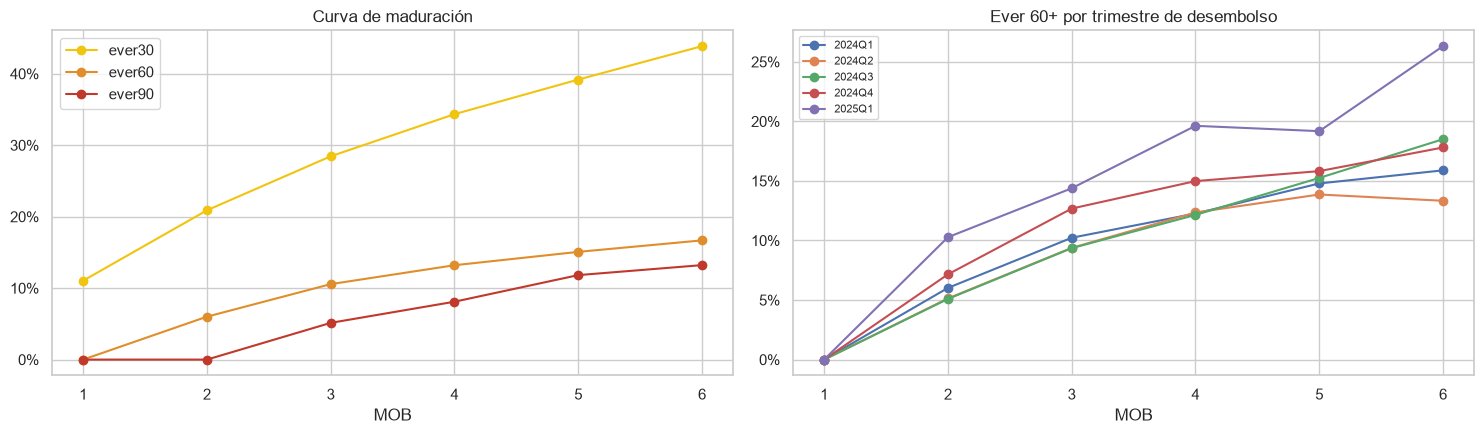

In [23]:
ever = car_ok.copy()
ever["max_mora_hasta_mob"] = ever.groupby("application_id")["mora_bucket"].cummax()
vint = ever.groupby("mob").agg(
    n=("application_id", "size"),
    ever30=("max_mora_hasta_mob", lambda s: (s >= 30).mean()),
    ever60=("max_mora_hasta_mob", lambda s: (s >= 60).mean()),
    ever90=("max_mora_hasta_mob", lambda s: (s >= 90).mean()))
display(vint.round(4))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for c, col in zip(["ever30", "ever60", "ever90"], ["#F1C40F", "#E08E2B", "#C0392B"]):
    ax[0].plot(vint.index, vint[c], marker="o", label=c, color=col)
ax[0].set_title("Curva de maduración"); ax[0].set_xlabel("MOB"); ax[0].legend()
ever["trimestre"] = ever.fecha_apertura.dt.to_period("Q").astype(str)
for q, g in ever.groupby("trimestre"):
    curva = g.groupby("mob")["max_mora_hasta_mob"].apply(lambda s: (s >= 60).mean())
    ax[1].plot(curva.index, curva.values, marker="o", label=q)
ax[1].set_title("Ever 60+ por trimestre de desembolso"); ax[1].set_xlabel("MOB"); ax[1].legend(fontsize=8)
for a in ax: a.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.show()

### 4.3 Sesgo por ventana de observación desigual
En la siguiente celda se cuantifica el sesgo de usar todo el historial disponible:
se compara la tasa de ever 60+ y ever 90+ según cuántos cortes tiene cada crédito.

In [24]:
perf = ever.groupby("application_id").agg(n_cortes=("mob", "max"), max_mora=("mora_bucket", "max"))
perf.groupby("n_cortes").agg(n=("max_mora", "size"),
                             ever60=("max_mora", lambda s: (s >= 60).mean()),
                             ever90=("max_mora", lambda s: (s >= 90).mean())).round(4)

,n,ever60,ever90
n_cortes,,,
3,992,0.1482,0.0736
4,1001,0.1459,0.0849
5,984,0.1626,0.1270
6,953,0.1668,0.1322


### 4.4 Sensibilidad de la tasa de default: umbral × ventana
En la siguiente celda se hace un análisis de sensibilidad de la tasa de default según
el umbral de mora (30+, 60+, 90+) y la ventana de observación (MOB 1–3 a 1–6). Para
cada ventana se usan sólo los créditos que la tienen completa, y se reporta cuánta
población se conserva. Se incluye como referencia la opción "todo el historial".

In [25]:
filas = []
for w in [3, 4, 5, 6]:
    sub = ever[ever.mob <= w].groupby("application_id").agg(n=("mob", "max"), mx=("mora_bucket", "max"))
    sub = sub[sub.n >= w]
    for t in [30, 60, 90]:
        filas.append({"ventana": f"MOB 1–{w}", "umbral": f"{t}+", "creditos": len(sub),
                      "pct_poblacion": len(sub) / len(perf), "tasa_default": (sub.mx >= t).mean()})
for t in [30, 60, 90]:
    filas.append({"ventana": "Todo el historial", "umbral": f"{t}+", "creditos": len(perf),
                  "pct_poblacion": 1.0, "tasa_default": (perf.max_mora >= t).mean()})
sens = pd.DataFrame(filas)
display(sens.pivot(index="ventana", columns="umbral", values="tasa_default").style.format("{:.2%}"))
sens.groupby("ventana")[["creditos", "pct_poblacion"]].first()

umbral,30+,60+,90+
ventana,,,
MOB 1–3,28.45%,10.56%,5.14%
MOB 1–4,34.34%,13.21%,8.10%
MOB 1–5,39.18%,15.07%,11.82%
MOB 1–6,43.86%,16.68%,13.22%
Todo el historial,37.12%,15.57%,10.41%


,creditos,pct_poblacion
ventana,,
MOB 1–3,3930,1.000000
MOB 1–4,2938,0.747583
MOB 1–5,1937,0.492875
MOB 1–6,953,0.242494
Todo el historial,3930,1.000000


### 4.5 Matriz de transición (roll rate)
En la siguiente celda se calcula una matriz de transición (*roll rate*): para los créditos
observados al menos 5 meses, qué porcentaje llega a 90+ en algún momento según su peor
mora en los primeros 3 cortes. Sirve para validar si un 60+ temprano anticipa el
incumplimiento grave (90+).

In [26]:
s3 = ever[ever.mob <= 3].groupby("application_id")["mora_bucket"].max().rename("max_mob3")
largo = perf[perf.n_cortes >= 5].join(s3)
display(pd.crosstab(largo.max_mob3, largo.max_mora >= 90, normalize="index")
          .rename(columns={True: "llega_a_90+", False: "no_llega"}).round(4))
cap = (largo.loc[largo.max_mora >= 90, "max_mob3"] >= 60).mean()
print(f"De los que llegan a 90+, {cap:.1%} ya estaban en 60+ al MOB 3")

max_mora,no_llega,llega_a_90+
max_mob3,,
0,0.9878,0.0122
30,0.8016,0.1984
60,0.1039,0.8961
90,0.0000,1.0000


De los que llegan a 90+, 62.9% ya estaban en 60+ al MOB 3


### 4.6 Definición elegida y construcción de la variable default
**Default = 1 si el crédito alcanza mora ≥ 60 días en alguno de los 3 primeros cortes
(MOB 1–3); 0 en otro caso.**

- Es la única ventana **completa para el 100 % de los créditos**: elimina el sesgo por
  tiempo de observación sin perder muestra.
- 90+ en MOB 1–3 sólo ocurre si el cliente no paga ninguna cuota (evento muy raro);
  con ventanas más largas, el 90+ obliga a descartar entre 25 % y 75 % de la población.
- El 60+ temprano es un precursor casi seguro del 90+ (ver matriz de transición).

En la siguiente celda se construye la variable default, se une al dataset de
solicitudes y se grafica la tasa de default por mes de solicitud.

Base de modelamiento: 3,930 | defaults: 415 | tasa: 10.56%


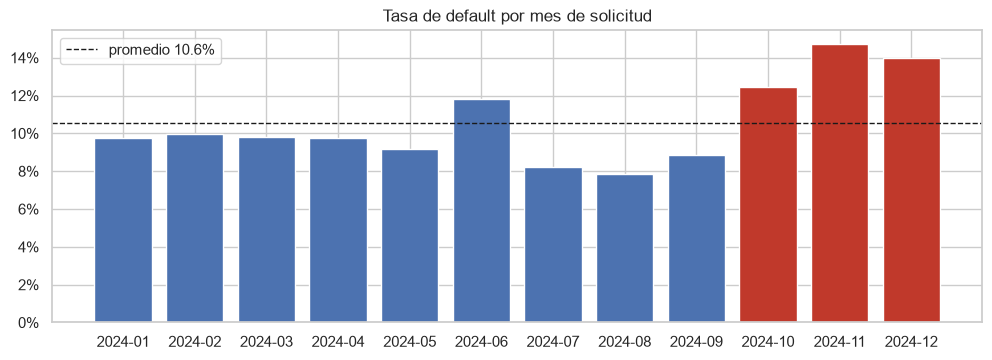

app_month,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12
size,339.0000,332.0000,326.0000,348.0000,327.0000,356.000,292.0000,331.0000,293.0000,338.0000,319.0000,329.0000
mean,0.0973,0.0994,0.0982,0.0977,0.0917,0.118,0.0822,0.0785,0.0887,0.1243,0.1473,0.1398


In [27]:
target = (ever[ever.mob <= 3].groupby("application_id")["mora_bucket"].max() >= 60).astype(int).rename("default")
abt = sol.merge(target.reset_index(), on="application_id", how="inner")
print(f"Base de modelamiento: {len(abt):,} | defaults: {abt.default.sum():,} | tasa: {abt.default.mean():.2%}")

abt["app_month"] = abt.application_date.dt.to_period("M")
dr = abt.groupby("app_month").default.agg(["size", "mean"])
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.bar(dr.index.astype(str), dr["mean"],
       color=["#C0392B" if str(m) >= "2024-10" else "#4C72B0" for m in dr.index])
ax.axhline(abt.default.mean(), ls="--", color="k", lw=1, label=f"promedio {abt.default.mean():.1%}")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Tasa de default por mes de solicitud"); ax.legend()
plt.show()
dr.T.round(4)

### Hallazgos – variable default

- **Curvas de maduración:** las tasas acumuladas siguen creciendo hasta MOB 6
  (ever 60+: 10,6 % en MOB 3 → 16,7 % en MOB 6), es decir, la cartera **no se ha
  estabilizado** en la ventana disponible. El ever 90+ es 0 en MOB 1–2 por construcción
  de la escala (la mora sube 30 días por corte).
- **Deterioro de cosechas recientes:** los desembolsos de 2024-Q4 y 2025-Q1 están por
  encima de las cosechas anteriores en casi todos los MOB (2025-Q1: 14,4 % de ever 60+
  en MOB 3 vs ≈ 9–10 % en 2024-Q1–Q3). Como todas las cosechas tienen la misma
  distribución de cortes, no es un efecto de madurez sino de **riesgo real mayor**.
- **Sesgo por ventana desigual:** con "todo el historial", el ever 90+ va de 7,4 % en
  créditos con 3 cortes a 13,2 % en créditos con 6, sólo por haber sido observados más
  tiempo. Esto confirma que se necesita una ventana fija.
- **Sensibilidad umbral × ventana:**

  | Ventana | 30+ | 60+ | 90+ | % población |
  |---|---|---|---|---|
  | MOB 1–3 | 28,5 % | **10,6 %** | 5,1 % | 100 % |
  | MOB 1–4 | 34,3 % | 13,2 % | 8,1 % | 75 % |
  | MOB 1–5 | 39,2 % | 15,1 % | 11,8 % | 49 % |
  | MOB 1–6 | 43,9 % | 16,7 % | 13,2 % | 24 % |
  | Todo el historial | 37,1 % | 15,6 % | 10,4 % | 100 % (sesgado) |

  Un umbral de 30+ casi triplicaría la tasa e incluiría mora técnica (olvidos de pago);
  90+ la reduciría a la mitad o forzaría a perder entre 25 % y 75 % de la muestra.
- **Roll rate:** el 89,6 % de los créditos en 60 al MOB 3 y el 100 % de los que están
  en 90 llegan a 90+, frente a sólo 1,2 % de los que estaban al día. El 60+ temprano
  es un **precursor casi seguro del incumplimiento grave**. Limitación: captura el
  62,9 % de los 90+ observados con ventana larga; el resto cae tarde y debe
  monitorearse cuando las cosechas maduren.
- **Resultado:** base de modelamiento de **3.930 créditos**, **415 defaults**, tasa de
  default **10,56 %**. Por mes de solicitud la tasa es estable entre 8 % y 12 % en
  ene–sep 2024 y **sube a 12,4 %–14,7 % en oct–dic 2024**.

## 5. Análisis exploratorio (EDA)

### 5.1 Funciones de apoyo
En la siguiente celda se definen dos funciones de apoyo para medir el poder
discriminante de cada variable por separado:
- **AUC univariada**: probabilidad de que un default tenga un valor más "riesgoso" que
  un no-default. Se orienta para que siempre sea ≥ 0,5 y se reporta la dirección del
  riesgo (+ = a mayor valor, más riesgo).
- **KS**: máxima distancia entre las distribuciones acumuladas de buenos y malos.  

También se corrigen los montos solicitados capturados en miles (validado en 3.6).

In [28]:
from sklearn.metrics import roc_auc_score, roc_curve

def auc_univariada(y, x):
    m = pd.notna(x)
    a = roc_auc_score(np.asarray(y)[m], np.asarray(x)[m])
    return (a, "+") if a >= 0.5 else (1 - a, "-")

def ks(y, score):
    fpr, tpr, _ = roc_curve(y, score)
    return float(np.max(np.abs(tpr - fpr)))

abt["flag_req_rescaled"] = (abt.requested_amount < 5000).astype(int)
abt["requested_amount_fix"] = np.where(abt.requested_amount < 5000,
                                       abt.requested_amount * 1000, abt.requested_amount)
print("Montos corregidos:", abt.flag_req_rescaled.sum())

Montos corregidos: 24


### 5.2 Tasa de default por quintiles de cada variable
En la siguiente celda se divide cada variable numérica en quintiles y se grafica la
tasa de default de cada uno. La línea roja es la tasa promedio. Permite ver la forma
de la relación con el riesgo (creciente, decreciente, en U o plana).

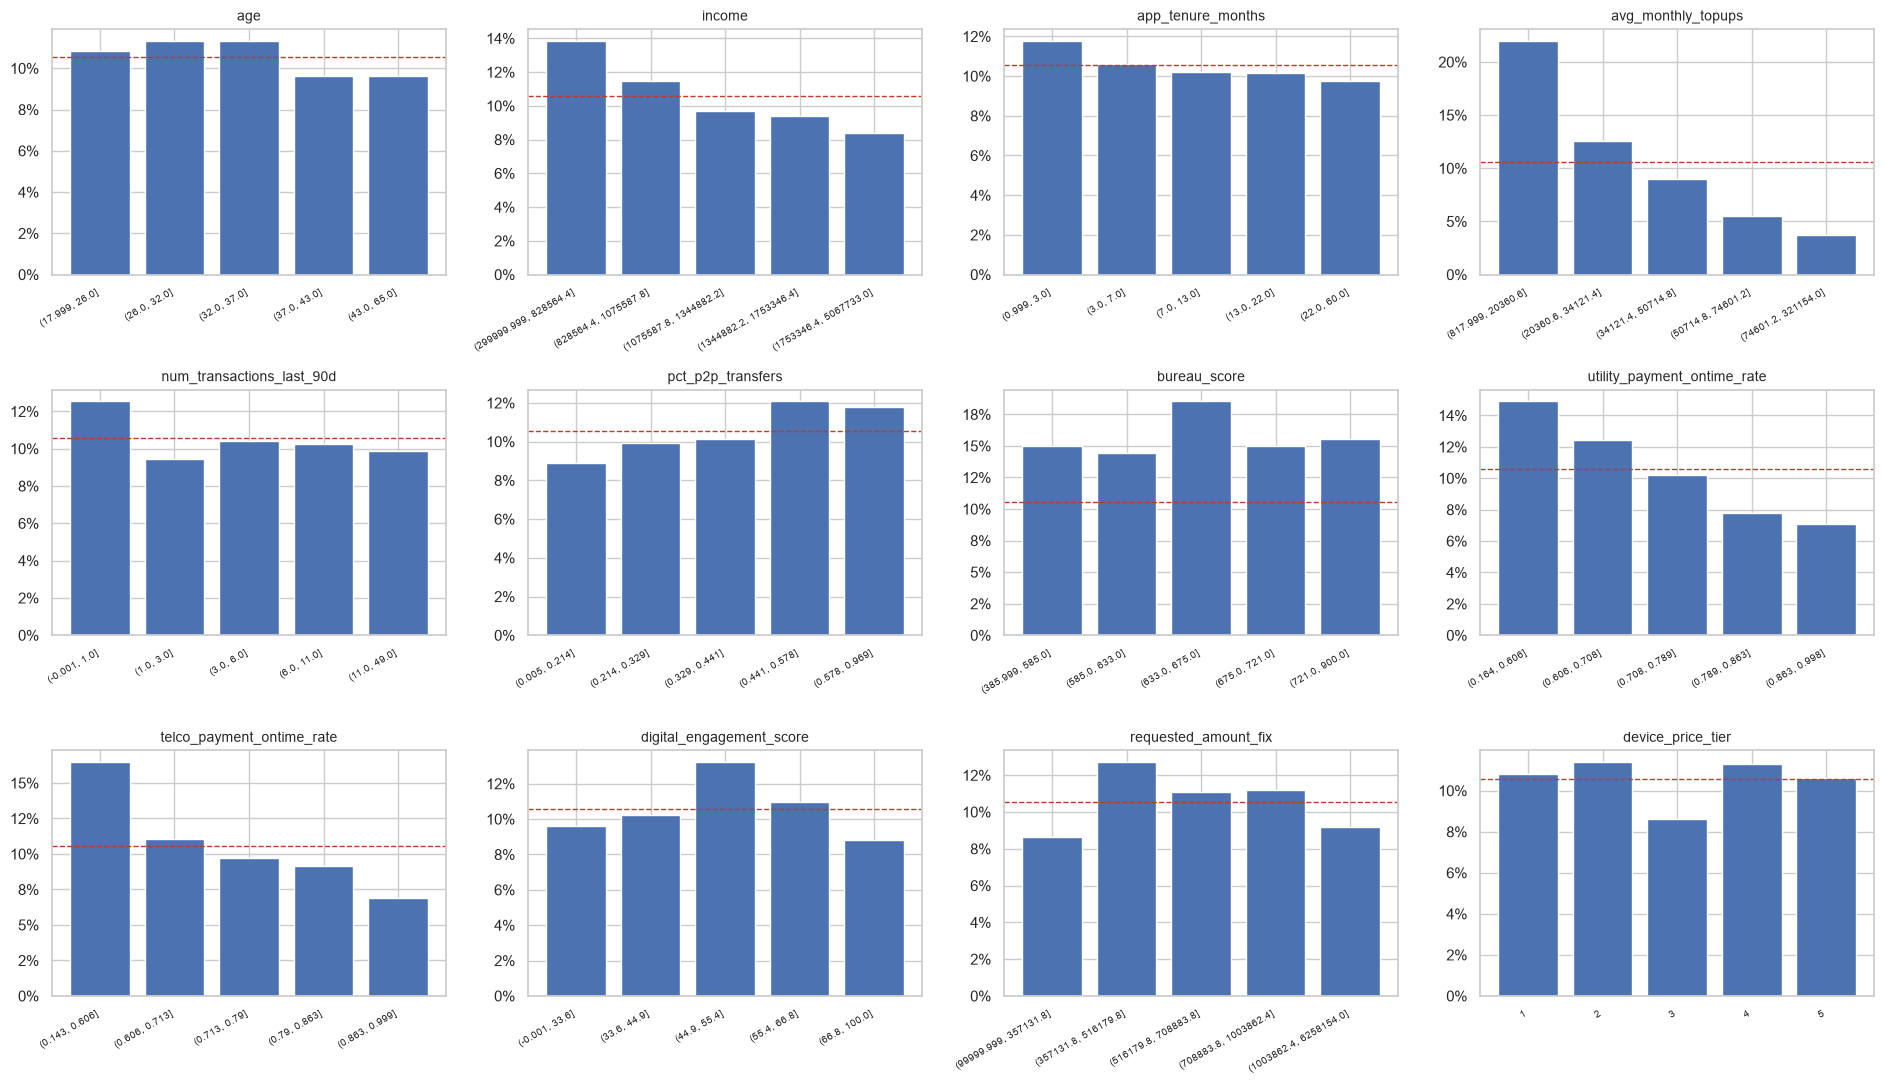

In [29]:
eda_num = ["age", "income", "app_tenure_months", "avg_monthly_topups", "num_transactions_last_90d",
           "pct_p2p_transfers", "bureau_score", "utility_payment_ontime_rate", "telco_payment_ontime_rate",
           "digital_engagement_score", "requested_amount_fix", "device_price_tier"]
base = abt.default.mean()

fig, axes = plt.subplots(3, 4, figsize=(19, 11))
for ax, c in zip(axes.ravel(), eda_num):
    z = abt[[c, "default"]].dropna()
    grupos = pd.qcut(z[c], 5, duplicates="drop") if z[c].nunique() > 5 else z[c]
    r = z.groupby(grupos, observed=True)["default"].mean()
    ax.bar(range(len(r)), r.values, color="#4C72B0")
    ax.set_xticks(range(len(r)))
    ax.set_xticklabels([str(i) for i in r.index], rotation=30, fontsize=7, ha="right")
    ax.axhline(base, ls="--", color="#C0392B", lw=1)
    ax.set_title(c, fontsize=10)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.show()

### 5.3 Poder discriminante univariado (AUC y KS)
En la siguiente celda se calcula la AUC y el KS de cada variable por separado contra
el default, ordenadas de mayor a menor poder discriminante.

In [30]:
filas = []
for c in eda_num + ["monto_bono_referidos"]:
    a, d = auc_univariada(abt["default"], abt[c])
    m = abt[c].notna()
    filas.append({"variable": c, "AUC": a, "direccion_riesgo": d,
                  "KS": ks(abt.default[m], abt[c][m] * (1 if d == "+" else -1)), "n": int(m.sum())})
uni = pd.DataFrame(filas).sort_values("AUC", ascending=False).set_index("variable")
uni.round(4)

,AUC,direccion_riesgo,KS,n
variable,,,,
avg_monthly_topups,0.6999,-,0.2957,3930
telco_payment_ontime_rate,0.5949,-,0.1524,3698
utility_payment_ontime_rate,0.5938,-,0.1584,3683
income,0.5523,-,0.0995,3930
pct_p2p_transfers,0.5357,+,0.0632,3930
app_tenure_months,0.5215,-,0.0390,3930
num_transactions_last_90d,0.5206,-,0.0464,3930
age,0.5123,-,0.0485,3930
device_price_tier,0.5080,-,0.0323,3930


### 5.4 Variables categóricas
En la siguiente celda se grafica la tasa de default por cada categoría de las variables
discretas (registro en buró, tipo de producto, sexo y si el ingreso fue recuperado),
con el tamaño de cada grupo.

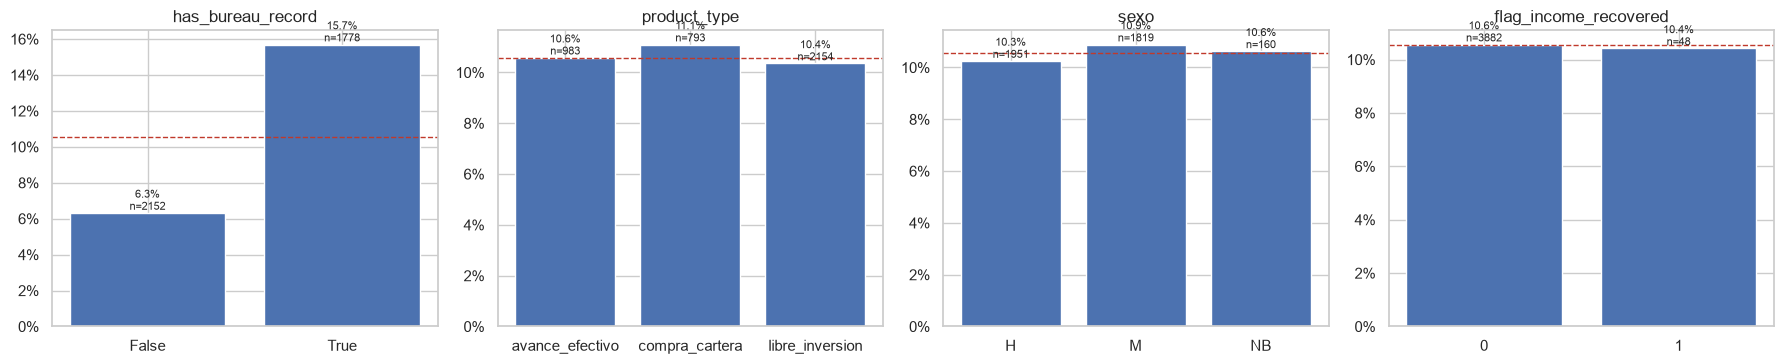

In [31]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, c in zip(axes, ["has_bureau_record", "product_type", "sexo", "flag_income_recovered"]):
    r = abt.groupby(c)["default"].agg(["mean", "size"])
    ax.bar(r.index.astype(str), r["mean"], color="#4C72B0")
    ax.axhline(base, ls="--", color="#C0392B", lw=1)
    for i, (v, n) in enumerate(zip(r["mean"], r["size"])):
        ax.text(i, v, f"{v:.1%}\nn={n}", ha="center", va="bottom", fontsize=8)
    ax.set_title(c)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.show()

### Hallazgos – análisis univariado y bivariado

- **Recargas mensuales (`avg_monthly_topups`)** es la variable individual más
  discriminante (AUC 0,70, KS 0,30). La relación es fuerte y monótona: la tasa de
  default cae de ≈ 22 % en el quintil más bajo a ≈ 3,6 % en el más alto. Interpretación:
  las recargas reflejan **flujo de caja real** del cliente, no declarado.
- **Datos alternativos de pago:** puntualidad en telco (AUC 0,59) y servicios públicos
  (AUC 0,59) muestran relación monótona decreciente (≈ 15–17 % de default en el
  quintil de peor pago vs ≈ 7 % en el mejor). Es el comportamiento de pago más
  cercano a un historial crediticio para clientes sin buró.
- **Ingreso declarado:** relación monótona decreciente (≈ 13,8 % → 8,3 %), pero con
  poder discriminante bajo (AUC 0,55).
- **% transferencias P2P:** relación creciente moderada (≈ 8,8 % → 12 %): mayor
  dependencia de transferencias entre personas se asocia a más riesgo.
- **Score de buró no discrimina** (AUC 0,51): dentro de quienes lo tienen, la tasa de
  default es plana (≈ 14–19 %) en todos los quintiles.
- **Engagement digital:** patrón no monótono (en U invertida, más riesgo en valores
  medios) y AUC ≈ 0,50 → señal débil y difícil de interpretar.
- **Sin señal relevante:** edad, antigüedad en la app, número de transacciones,
  monto solicitado, tier del dispositivo y bono de referidos (AUC ≤ 0,52).
- **Registro en buró (hallazgo clave):** los clientes **con** buró incumplen 15,7 %
  vs **6,3 %** los thin-file (≈ 2,5 veces más). Contrario a la intuición de que "sin
  historial = más riesgo": en esta población tener buró parece indicar
  **endeudamiento previo**.
- **Tipo de producto y sexo:** sin diferencias relevantes (10,3 %–11,1 %).
- **Ingresos recuperados:** misma tasa de default que el resto (10,4 % vs 10,6 %),
  lo que confirma que la recuperación no introdujo un grupo con comportamiento distinto.

### 5.5 ¿Hay poblaciones diferentes? Con buró vs. sin buró
En la siguiente celda se compara el perfil promedio de los clientes con y sin registro
en buró: tasa de default y valor medio de las principales variables. El objetivo es
ver si son poblaciones con características distintas o sólo con niveles de riesgo distintos.

In [32]:
abt["segmento"] = np.where(abt.has_bureau_record, "Con buró", "Sin buró")
display(abt.segmento.value_counts().to_frame("n").T)
abt.groupby("segmento")[["default", "avg_monthly_topups", "utility_payment_ontime_rate",
                          "telco_payment_ontime_rate", "digital_engagement_score", "income", "age",
                          "app_tenure_months", "pct_p2p_transfers", "device_price_tier"]].mean().T.round(3)

segmento,Sin buró,Con buró
n,2152,1778


segmento,Con buró,Sin buró
default,0.157,0.063
avg_monthly_topups,49439.042,49782.751
utility_payment_ontime_rate,0.731,0.729
telco_payment_ontime_rate,0.729,0.734
digital_engagement_score,50.903,49.672
income,1326927.939,1338411.206
age,34.657,35.009
app_tenure_months,13.150,13.775
pct_p2p_transfers,0.407,0.391
device_price_tier,2.366,2.417


En la siguiente celda se grafica la tasa de default por quintil de las variables más
predictivas, separando cada segmento. Si las curvas son paralelas, la variable ordena el
riesgo igual en ambos grupos y sólo cambia el nivel; si se cruzan, el efecto es distinto.
Además se calcula la AUC univariada de cada variable dentro de cada segmento.

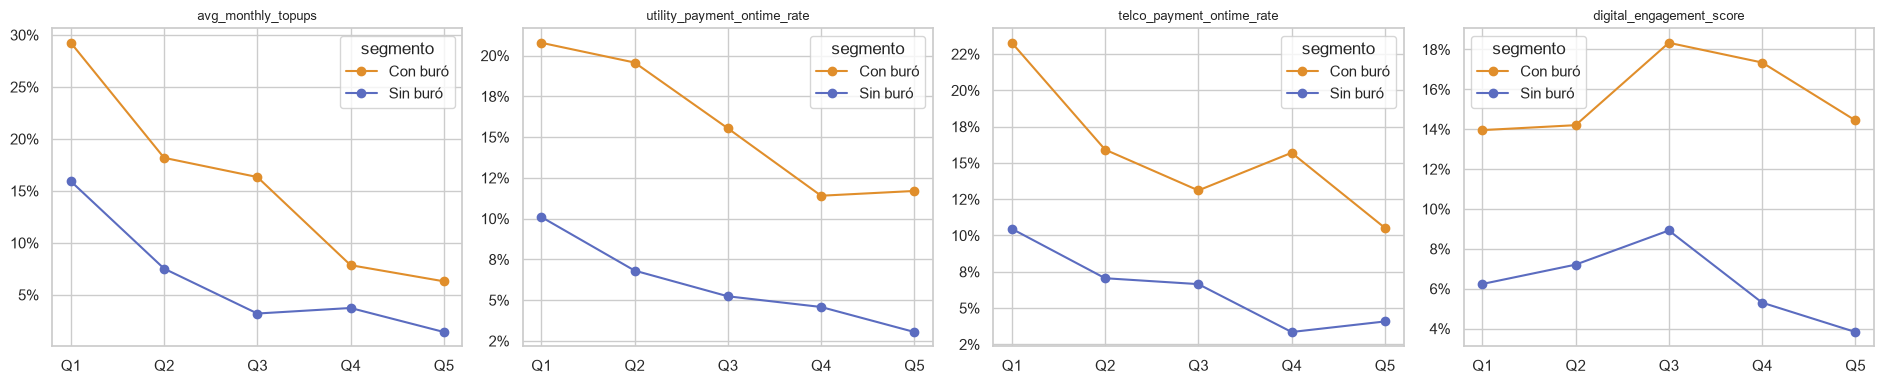

Con buró {'avg_monthly_topups': 0.686, 'utility_payment_ontime_rate': 0.585, 'telco_payment_ontime_rate': 0.582, 'digital_engagement_score': 0.516, 'income': 0.551, 'bureau_score': 0.507}
Sin buró {'avg_monthly_topups': 0.733, 'utility_payment_ontime_rate': 0.623, 'telco_payment_ontime_rate': 0.619, 'digital_engagement_score': 0.539, 'income': 0.558}


In [34]:
vars_seg = ["avg_monthly_topups", "utility_payment_ontime_rate", "telco_payment_ontime_rate", "digital_engagement_score"]
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for ax, c in zip(axes, vars_seg):
    z = abt[[c, "default", "segmento"]].dropna()
    z["q"] = pd.qcut(z[c], 5, labels=[f"Q{i}" for i in range(1, 6)])
    z.groupby(["segmento", "q"], observed=True)["default"].mean().unstack(0).plot(
        ax=ax, marker="o", color=["#E08E2B", "#5B6CC0"])
    ax.set_title(c, fontsize=9); ax.set_xlabel("")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.show()

for s, g in abt.groupby("segmento"):
    print(s, {c: round(auc_univariada(g.default, g[c])[0], 3)
              for c in vars_seg + ["income", "bureau_score"] if g[c].notna().sum() > 50})

### 5.6 Correlaciones entre variables
En la siguiente celda se calcula la matriz de correlación de Spearman (basada en rangos,
robusta a atípicos y a relaciones no lineales monótonas) entre las variables numéricas,
y se listan los pares con correlación absoluta mayor a 0,5 (riesgo de multicolinealidad).

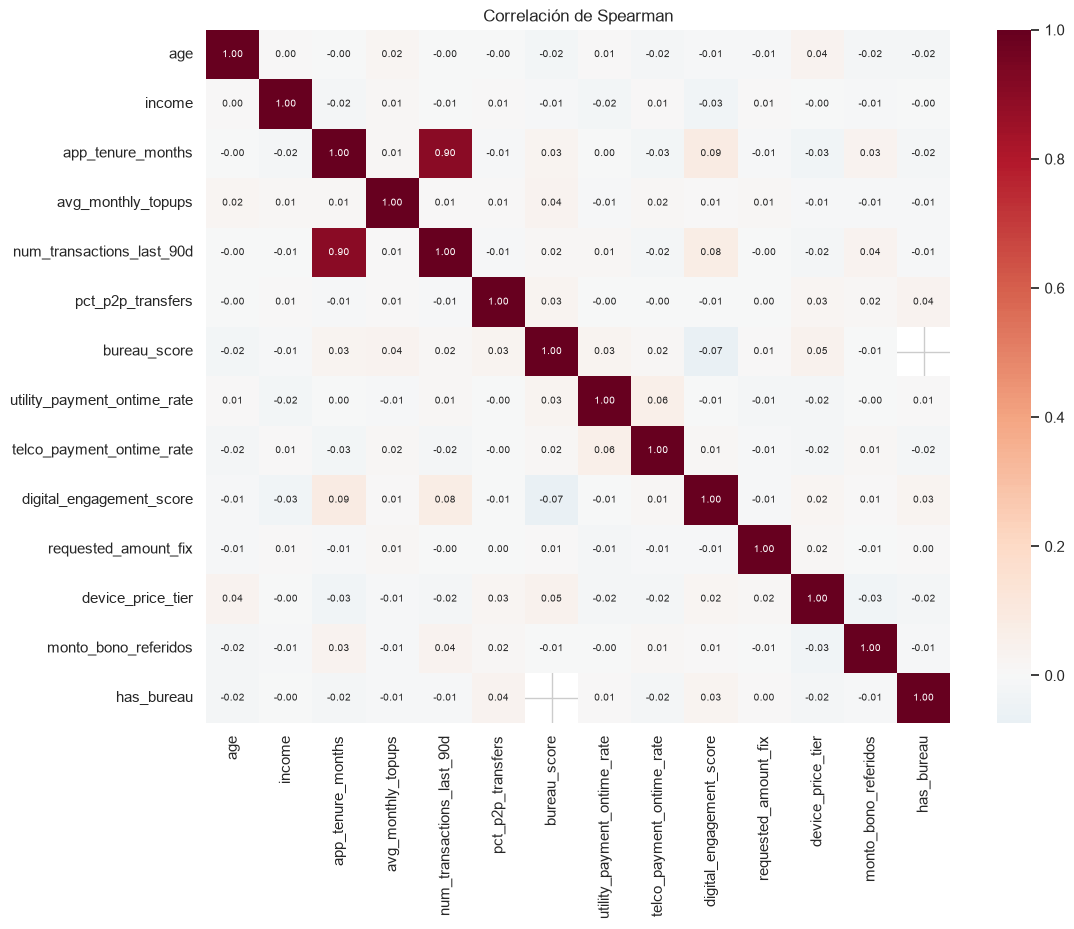

Pares con |rho| > 0,5: {('app_tenure_months', 'num_transactions_last_90d'): 0.903}


In [35]:
corr = abt[eda_num + ["monto_bono_referidos"]].assign(
    has_bureau=abt.has_bureau_record.astype(int)).corr(method="spearman")
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, annot_kws={"size": 7})
plt.title("Correlación de Spearman"); plt.show()

pares = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
print("Pares con |rho| > 0,5:", pares[pares.abs() > 0.5].round(3).to_dict())

### 5.7 Nulos en datos alternativos
En la siguiente celda se evalúa si los nulos de utility y telco son aleatorios:
se compara la tasa de default entre registros informados y nulos, cuántos casos tienen
ambas variables nulas, y si el porcentaje de nulos cambia según el segmento de buró.

In [36]:
for c in ["utility_payment_ontime_rate", "telco_payment_ontime_rate"]:
    print(c)
    display(abt.groupby(abt[c].isna())["default"].agg(["mean", "size"])
              .rename(index={False: "informado", True: "nulo"}).T.round(4))
print("Nulos simultáneos en ambas:",
      (abt.utility_payment_ontime_rate.isna() & abt.telco_payment_ontime_rate.isna()).sum())
abt.groupby("segmento")[["utility_payment_ontime_rate", "telco_payment_ontime_rate"]].apply(
    lambda d: d.isna().mean()).round(4)

utility_payment_ontime_rate


utility_payment_ontime_rate,informado,nulo
mean,0.1048,0.1174
size,3683.0000,247.0000


telco_payment_ontime_rate


telco_payment_ontime_rate,informado,nulo
mean,0.1065,0.0905
size,3698.0000,232.0000


Nulos simultáneos en ambas: 18


,utility_payment_ontime_rate,telco_payment_ontime_rate
segmento,,
Con buró,0.0456,0.0444
Sin buró,0.0771,0.0711


### 5.8 Deriva temporal de las variables
En la siguiente celda se grafica el promedio mensual (por mes de solicitud) de las
principales variables, del % de clientes con buró y de la tasa de default. La franja gris
marca oct–dic 2024. Sirve para detectar cambios en la población a lo largo del tiempo
que puedan afectar la estabilidad del modelo.

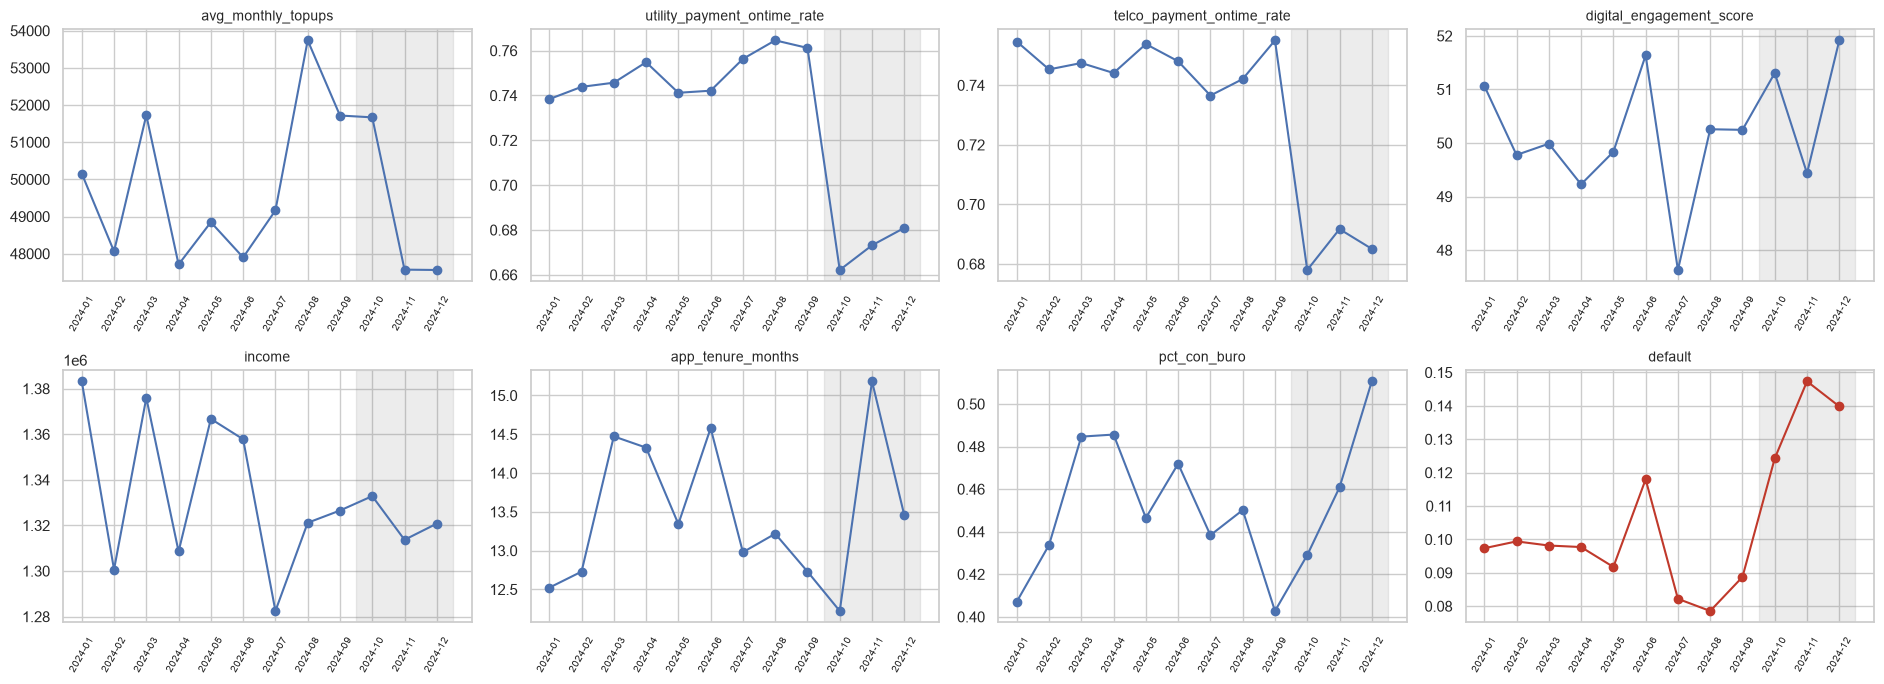

app_month,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12
avg_monthly_topups,50157.413,48061.883,51726.276,47709.626,48847.752,47899.427,49164.462,53740.417,51717.860,51668.148,47570.821,47561.404
utility_payment_ontime_rate,0.738,0.744,0.746,0.755,0.741,0.742,0.756,0.765,0.761,0.662,0.673,0.681
telco_payment_ontime_rate,0.755,0.745,0.747,0.744,0.754,0.748,0.737,0.742,0.755,0.678,0.692,0.685
digital_engagement_score,51.069,49.777,49.987,49.228,49.835,51.637,47.629,50.257,50.246,51.306,49.435,51.916
income,1383203.805,1300657.262,1375968.764,1308557.830,1366733.183,1357802.003,1282460.908,1321165.819,1326532.413,1332852.500,1313685.429,1320799.453
app_tenure_months,12.522,12.729,14.472,14.328,13.343,14.579,12.979,13.218,12.730,12.222,15.182,13.456
default,0.097,0.099,0.098,0.098,0.092,0.118,0.082,0.079,0.089,0.124,0.147,0.140
pct_con_buro,0.407,0.434,0.485,0.486,0.446,0.472,0.438,0.450,0.403,0.429,0.461,0.511


In [37]:
vars_deriva = ["avg_monthly_topups", "utility_payment_ontime_rate", "telco_payment_ontime_rate",
               "digital_engagement_score", "income", "app_tenure_months"]
mm = abt.groupby("app_month")[vars_deriva + ["default"]].mean()
mm["pct_con_buro"] = abt.groupby("app_month").has_bureau_record.mean()

fig, axes = plt.subplots(2, 4, figsize=(19, 7))
for ax, c in zip(axes.ravel(), vars_deriva + ["pct_con_buro", "default"]):
    ax.plot(mm.index.astype(str), mm[c], marker="o", color="#C0392B" if c == "default" else "#4C72B0")
    ax.axvspan(8.5, 11.5, color="grey", alpha=.15)
    ax.set_title(c, fontsize=10); ax.tick_params(axis="x", rotation=60, labelsize=7)
plt.tight_layout(); plt.show()
mm.T.round(3)

En la siguiente celda se compara la distribución completa de las tasas de pago
de utility y telco entre ene–sep y oct–dic 2024, para entender si el cambio es un
desplazamiento general o una modificación en una parte específica de la distribución.

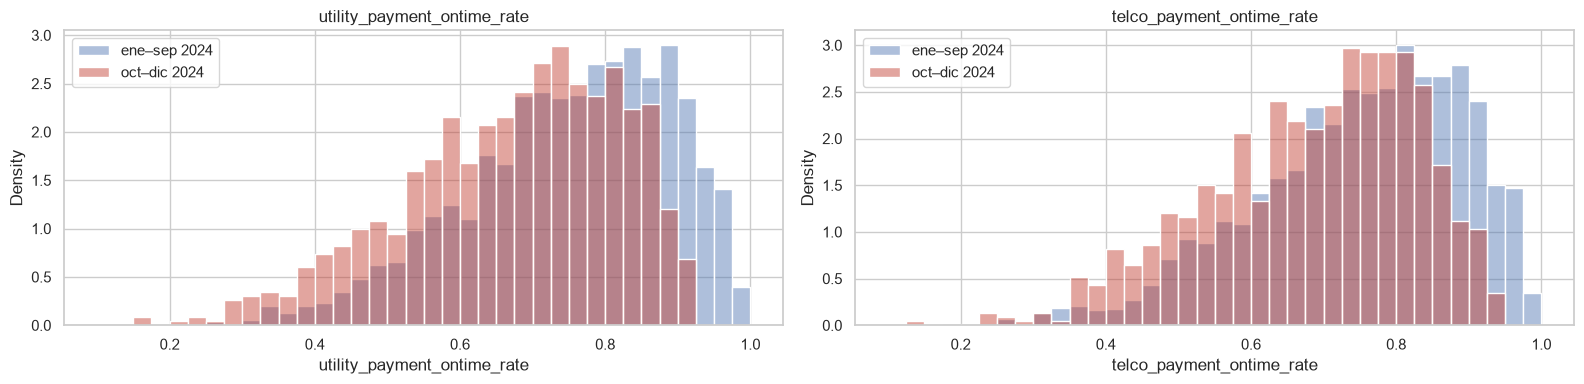

utility_payment_ontime_rate: máx ene–sep = 0.998 | máx oct–dic = 0.917 | % > 0,9: 13.2% → 1.5%
telco_payment_ontime_rate: máx ene–sep = 0.999 | máx oct–dic = 0.936 | % > 0,9: 13.2% → 3.0%


In [39]:
corte = pd.Timestamp("2024-10-01")
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
for ax, c in zip(axes, ["utility_payment_ontime_rate", "telco_payment_ontime_rate"]):
    for etiqueta, g, col in [("ene–sep 2024", abt[abt.application_date < corte], "#4C72B0"),
                             ("oct–dic 2024", abt[abt.application_date >= corte], "#C0392B")]:
        sns.histplot(g[c].dropna(), bins=np.arange(0.1, 1.01, 0.025), stat="density",
                     ax=ax, color=col, alpha=.45, label=etiqueta)
    ax.set_title(c); ax.legend()
plt.tight_layout(); plt.show()

for c in ["utility_payment_ontime_rate", "telco_payment_ontime_rate"]:
    a, b = abt.loc[abt.application_date < corte, c], abt.loc[abt.application_date >= corte, c]
    print(f"{c}: máx ene–sep = {a.max():.3f} | máx oct–dic = {b.max():.3f} | "
          f"% > 0,9: {(a > .9).mean():.1%} → {(b > .9).mean():.1%}")

### Hallazgos – poblaciones, correlaciones, nulos y deriva

**5.5 Con buró vs. sin buró**
- Las dos poblaciones tienen un **perfil prácticamente idéntico** (recargas, pagos
  alternativos, ingreso, edad, antigüedad, P2P y dispositivo con promedios casi iguales),
  pero un **nivel de riesgo muy distinto**: 15,7 % vs 6,3 %.
- Las curvas por quintil son **aproximadamente paralelas**: recargas y pagos alternativos
  ordenan el riesgo en ambos segmentos y el segmento con buró está desplazado hacia arriba.
  El ordenamiento es incluso mejor en thin-file (AUC recargas 0,73 vs 0,69; utility 0,62 vs 0,59).
- Implicación: más que dos modelos distintos, parece suficiente **un modelo único con el
  indicador de buró como variable** (desplaza el nivel de riesgo). Se validará
  comparando contra modelos segmentados.
- Dentro del segmento con buró, `bureau_score` no discrimina (AUC 0,51).

**5.6 Correlaciones**
- El único par fuertemente correlacionado es `app_tenure_months` ↔ `num_transactions_last_90d`
  (ρ = 0,90): ambas miden actividad acumulada en la app y no deben entrar juntas al modelo.
- El resto de variables es prácticamente independiente (|ρ| < 0,1); incluso utility y telco
  (ρ ≈ 0,06) miden comportamientos distintos, lo que justifica combinarlas.

**5.7 Nulos en datos alternativos**
- ~6 % de nulos en cada variable, casi nunca simultáneos (18 casos) y con tasa de default
  similar a los informados (utility 11,7 % vs 10,5 %; telco 9,1 % vs 10,7 %).
- Son algo más frecuentes en thin-file (≈ 7–8 % vs ≈ 4,5 %): no son completamente
  aleatorios. **No se

## 6. Tratamiento de datos y feature engineering

### 6.1 Resumen de tratamientos
| Problema | Tratamiento |
|---|---|
| 49 ingresos con formato corrupto | Recuperados por regla determinística + `flag_income_recovered` |
| 24 montos solicitados en miles | × 1.000 + `flag_req_rescaled` (validado contra saldo MOB 1) |
| Pico de edad = 18 | `flag_age_18`; la edad se usa agrupada en rangos |
| Nulos utility/telco (~6 %) | Categoría "Missing" propia en el binning (sin imputar) |
| `bureau_score` nulo en thin-file | Nulo estructural: se representa con `has_bureau` (el score no discrimina) |
| Atípicos en montos y recargas | No se recortan: el binning agrupa los extremos en el último rango |
| `monto_bono_referidos` | 98 % ceros, AUC ≈ 0,50 → se evalúa pero se espera excluir |
| `sexo` | **Excluida por equidad** (variable protegida); sólo se usa para auditar sesgo |
| `application_id`, fechas | Identificadores / sólo para particionar |

### 6.2 Variables derivadas
En la siguiente celda se crean los indicadores de calidad de datos y variables derivadas
con sentido de negocio:
- `topups_to_income`: recargas como proporción del ingreso (capacidad de pago observada vs. declarada).
- `req_to_income`: monto solicitado / ingreso (nivel de apalancamiento).
- `alt_pay_avg` y `alt_pay_min`: promedio y mínimo de la puntualidad en utility y telco
  (comportamiento de pago consolidado; el mínimo captura al peor pagador en alguno de los dos).
  Si falta una fuente se usa la disponible.
- `n_alt_missing`: número de fuentes alternativas faltantes.
- `tx_per_tenure`: transacciones de 90 días ajustadas por antigüedad (≤ 3 meses).
Al final se define la lista de variables candidatas al modelo.

In [40]:
abt["flag_age_18"] = (abt.age == 18).astype(int)
abt["has_bureau"] = abt.has_bureau_record.astype(int)
abt["topups_to_income"] = abt.avg_monthly_topups / abt.income
abt["req_to_income"] = abt.requested_amount_fix / abt.income
abt["alt_pay_avg"] = abt[["utility_payment_ontime_rate", "telco_payment_ontime_rate"]].mean(axis=1)
abt["alt_pay_min"] = abt[["utility_payment_ontime_rate", "telco_payment_ontime_rate"]].min(axis=1)
abt["n_alt_missing"] = abt[["utility_payment_ontime_rate", "telco_payment_ontime_rate"]].isna().sum(axis=1)
abt["tx_per_tenure"] = abt.num_transactions_last_90d / np.minimum(abt.app_tenure_months, 3)

CANDIDATAS = ["age", "income", "app_tenure_months", "avg_monthly_topups", "num_transactions_last_90d",
              "pct_p2p_transfers", "device_price_tier", "has_bureau", "bureau_score",
              "utility_payment_ontime_rate", "telco_payment_ontime_rate", "digital_engagement_score",
              "requested_amount_fix", "topups_to_income", "req_to_income", "alt_pay_avg", "alt_pay_min",
              "n_alt_missing", "tx_per_tenure", "flag_age_18", "monto_bono_referidos"]
CAT_CANDIDATAS = ["product_type"]

print(len(CANDIDATAS) + len(CAT_CANDIDATAS), "variables candidatas")
abt[["topups_to_income", "req_to_income", "alt_pay_avg", "alt_pay_min", "tx_per_tenure"]].describe().round(3)

22 variables candidatas


,topups_to_income,req_to_income,alt_pay_avg,alt_pay_min,tx_per_tenure
count,3930.000,3930.000,3912.000,3912.000,3930.000
mean,0.045,0.663,0.731,0.661,2.346
std,0.040,0.608,0.112,0.143,2.261
min,0.001,0.028,0.290,0.144,0.000
25%,0.018,0.294,0.662,0.564,0.667
50%,0.033,0.494,0.740,0.675,1.667
75%,0.060,0.827,0.812,0.766,3.333
max,0.411,12.395,0.996,0.996,16.333


## 7. División del dataset
### 7.1 Train / Test / OOT
En la siguiente celda se divide la base en tres muestras:
- **OOT (fuera de tiempo):** solicitudes de oct–dic 2024. Simula el uso del modelo en un
  periodo posterior al de construcción y captura la deriva observada en el EDA.
- **Desarrollo (ene–sep 2024):** partición aleatoria **estratificada por default**
  70 % train / 30 % test, con semilla fija para reproducibilidad.
Se resume el tamaño, número de defaults, tasa de default y % thin-file de cada muestra,
y se guardan los archivos en `data/processed/`.

In [41]:
from sklearn.model_selection import train_test_split

SEED = 42
PROC = Path("../data/processed")
PROC.mkdir(parents=True, exist_ok=True)

OOT_INICIO = pd.Timestamp("2024-10-01")
dev = abt[abt.application_date < OOT_INICIO]
oot = abt[abt.application_date >= OOT_INICIO].copy()
train, test = train_test_split(dev, test_size=0.30, stratify=dev["default"], random_state=SEED)
train, test = train.copy(), test.copy()
for nombre, d in [("train", train), ("test", test), ("oot", oot)]:
    d["split"] = nombre

splits = pd.concat([train, test, oot])
resumen_splits = splits.groupby("split", sort=False).agg(
    n=("default", "size"), defaults=("default", "sum"), tasa_default=("default", "mean"),
    pct_sin_buro=("has_bureau", lambda s: 1 - s.mean()),
    desde=("application_date", "min"), hasta=("application_date", "max"))
display(resumen_splits)

cols_export = ["application_id", "split", "application_date", "default", "sexo",
               "has_bureau_record", "flag_income_recovered", "flag_req_rescaled"] + CANDIDATAS + CAT_CANDIDATAS
for nombre, d in [("train", train), ("test", test), ("oot", oot)]:
    d[cols_export].to_csv(PROC / f"{nombre}.csv", index=False)
splits[cols_export].to_csv(PROC / "abt_modelamiento.csv", index=False)
print("Archivos guardados en data/processed/")

,n,defaults,tasa_default,pct_sin_buro,desde,hasta
split,,,,,,
train,2060,196,0.095146,0.549029,2024-01-01,2024-09-30
test,884,84,0.095023,0.559955,2024-01-01,2024-09-30
oot,986,135,0.136917,0.533469,2024-10-01,2024-12-31


Archivos guardados en data/processed/


### Hallazgos – variables derivadas y división

- **Variables derivadas:** las recargas representan en mediana el 3,3 % del ingreso
  declarado; el monto solicitado equivale en mediana a la mitad del ingreso mensual
  (`req_to_income` 0,49), con casos extremos de hasta 12 veces. `alt_pay_avg` queda nula
  sólo en los 18 casos sin ninguna fuente alternativa.
- **División:**

  | Muestra | Periodo | n | Defaults | Tasa default | % sin buró |
  |---|---|---|---|---|---|
  | Train | ene–sep 2024 | 2.060 | 196 | 9,5 % | 54,9 % |
  | Test | ene–sep 2024 | 884 | 84 | 9,5 % | 56,0 % |
  | OOT | oct–dic 2024 | 986 | 135 | **13,7 %** | 53,3 % |

  La estratificación garantiza la misma tasa de default en train y test. El OOT tiene una
  tasa 4 pp mayor, consistente con el deterioro observado en el EDA: será una prueba
  exigente de estabilidad para el modelo.
- **Muestra pequeña:** con ≈ 200 malos en train, se prioriza un modelo con **pocos
  parámetros** y bins con suficiente población para evitar sobreajuste.

### 7.2 Estabilidad de las variables entre muestras (CSI)
En la siguiente celda se importan las funciones de riesgo desde `src/risk_utils.py` y se
calcula el CSI (PSI aplicado a cada variable) comparando test y OOT contra train. Cortes
por deciles de train; nulos como categoría propia. Lectura: < 0,10 estable;
0,10–0,25 cambio moderado; > 0,25 cambio significativo.

In [42]:
import sys
sys.path.insert(0, str(Path("../src").resolve()))
from risk_utils import (auc, gini, ks, auc_univariada, bootstrap_ci, tabla_deciles, psi, psi_categorica,
                        lectura_psi, WoEBinner, ajustar_binners, woe_transform, resumen_iv)

csi = [{"variable": c, "CSI_test": psi(train[c], test[c]), "CSI_oot": psi(train[c], oot[c])} for c in CANDIDATAS]
csi += [{"variable": c, "CSI_test": psi_categorica(train[c], test[c]),
         "CSI_oot": psi_categorica(train[c], oot[c])} for c in CAT_CANDIDATAS]
csi = pd.DataFrame(csi).set_index("variable").sort_values("CSI_oot", ascending=False)
csi["lectura_oot"] = csi.CSI_oot.map(lectura_psi)
csi.round(4)

,CSI_test,CSI_oot,lectura_oot
variable,,,
utility_payment_ontime_rate,0.0189,0.7975,Cambio significativo
alt_pay_avg,0.0092,0.5404,Cambio significativo
alt_pay_min,0.0272,0.3567,Cambio significativo
telco_payment_ontime_rate,0.0192,0.2853,Cambio significativo
age,0.0213,0.0221,Estable
app_tenure_months,0.0142,0.0170,Estable
num_transactions_last_90d,0.0082,0.0139,Estable
income,0.0171,0.0125,Estable
digital_engagement_score,0.0350,0.0122,Estable


## 8. Binning WoE e Information Value
### 8.1 Binning supervisado e IV (ajustado sólo en train)
En la siguiente celda se ajusta el binning de cada variable **sólo con train** (para no
filtrar información de test ni OOT): árbol de decisión con máximo 6 bins, cada bin con al
menos 5 % de la muestra, nulos en bin propio y monotonía forzada en el sentido de la
relación con el default. Excepción: `digital_engagement_score`, cuyo patrón no es monótono
(EDA 5.2), se limita a 3 bins de al menos 10 % para no sobreajustar ruido.
Luego se calcula y grafica el IV de cada variable.

,iv,n_bins,poder_predictivo
avg_monthly_topups,0.4916,5,Fuerte
topups_to_income,0.3123,5,Fuerte
alt_pay_avg,0.2293,5,Media
bureau_score,0.2213,3,Media
has_bureau,0.2029,2,Media
alt_pay_min,0.1742,5,Media
telco_payment_ontime_rate,0.1515,5,Media
utility_payment_ontime_rate,0.1506,6,Media
pct_p2p_transfers,0.0881,4,Débil
requested_amount_fix,0.0611,3,Débil


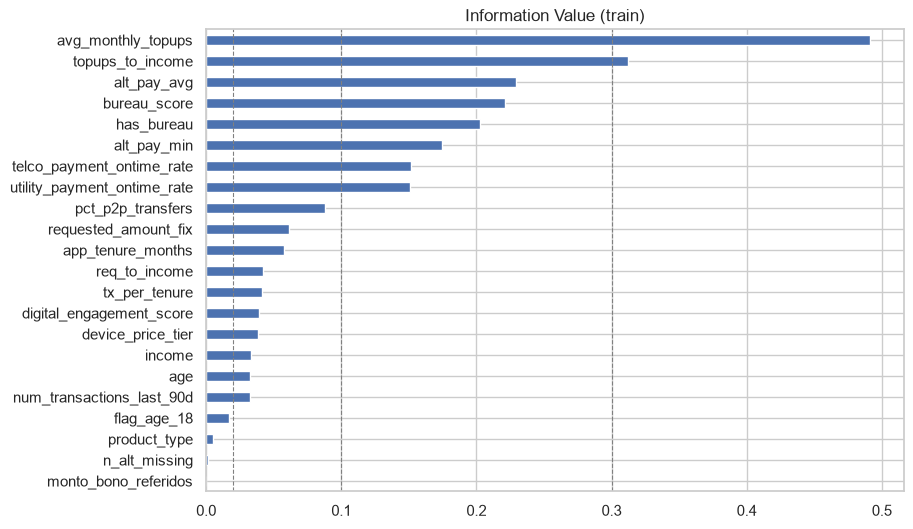

In [43]:
MONO = {c: "auto" for c in CANDIDATAS}
MONO["digital_engagement_score"] = None
binners = ajustar_binners(train, train["default"], CANDIDATAS, CAT_CANDIDATAS,
                          monotonic=MONO, max_bins=6, min_bin_pct=0.05)
binners["digital_engagement_score"] = WoEBinner(max_bins=3, min_bin_pct=0.10, monotonic=None).fit(
    train["digital_engagement_score"], train["default"])

ivs = resumen_iv(binners)
display(ivs.round(4))
plt.figure(figsize=(9, 6))
ivs["iv"].sort_values().plot.barh(color="#4C72B0")
for x in [0.02, 0.1, 0.3]:
    plt.axvline(x, ls="--", color="grey", lw=.8)
plt.title("Information Value (train)"); plt.show()

### 8.2 Detalle de los bins de las variables más predictivas
En la siguiente celda se muestra, para las 8 variables con mayor IV, la tabla de cada bin:
población, malos, tasa de default, WoE e IV aportado. Permite verificar que los cortes
tienen sentido de negocio y que la tendencia del riesgo es coherente.

In [44]:
for c in ivs.index[:8]:
    print(f"\n=== {c}  (IV = {binners[c].iv_:.3f})")
    display(binners[c].table_[["n", "pct_n", "malos", "tasa_malos", "woe", "iv"]].round(4))


=== avg_monthly_topups  (IV = 0.492)


,n,pct_n,malos,tasa_malos,woe,iv
bin,,,,,,
"(-inf, 1.302e+04]",201,0.0976,58,0.2886,1.3437,0.2927
"(1.302e+04, 2.818e+04]",444,0.2155,49,0.1104,0.1629,0.0061
"(2.818e+04, 4.548e+04]",485,0.2354,43,0.0887,-0.0786,0.0014
"(4.548e+04, 1.02e+05]",760,0.3689,42,0.0553,-0.5866,0.1002
"(1.02e+05, inf]",170,0.0825,4,0.0235,-1.3699,0.0911



=== topups_to_income  (IV = 0.312)


,n,pct_n,malos,tasa_malos,woe,iv
bin,,,,,,
"(-inf, 0.007371]",147,0.0714,37,0.2517,1.1604,0.1505
"(0.007371, 0.01058]",103,0.0500,18,0.1748,0.7103,0.0337
"(0.01058, 0.04019]",955,0.4636,92,0.0963,0.0072,0.0000
"(0.04019, 0.05412]",252,0.1223,21,0.0833,-0.1355,0.0021
"(0.05412, inf]",603,0.2927,28,0.0464,-0.7643,0.1259



=== alt_pay_avg  (IV = 0.229)


...

,n,pct_n,malos,tasa_malos,woe,iv
bin,,,,,,
"(-inf, 0.4615]",135,0.0655,28,0.2074,0.9134,0.0785
"(0.4615, 0.6355]",579,0.2811,71,0.1226,0.2793,0.0245
"(0.6355, 0.7335]",540,0.2621,47,0.0870,-0.0998,0.0025
"(0.7335, inf]",795,0.3859,50,0.0629,-0.4511,0.0654
Missing,11,0.0053,0,0.0000,0.9134,0.0033



=== telco_payment_ontime_rate  (IV = 0.151)


,n,pct_n,malos,tasa_malos,woe,iv
bin,,,,,,
"(-inf, 0.5165]",145,0.0704,25,0.1724,0.6881,0.0440
"(0.5165, 0.6355]",267,0.1296,37,0.1386,0.4251,0.0278
"(0.6355, 0.7445]",433,0.2102,51,0.1178,0.2359,0.0129
"(0.7445, inf]",1097,0.5325,76,0.0693,-0.3507,0.0568
Missing,118,0.0573,7,0.0593,-0.4581,0.0101



=== utility_payment_ontime_rate  (IV = 0.151)


,n,pct_n,malos,tasa_malos,woe,iv
bin,,,,,,
"(-inf, 0.5645]",228,0.1107,37,0.1623,0.6082,0.0522
"(0.5645, 0.7665]",708,0.3437,81,0.1144,0.1976,0.0145
"(0.7665, 0.8065]",206,0.1000,18,0.0874,-0.0825,0.0007
"(0.8065, 0.9295]",631,0.3063,40,0.0634,-0.4426,0.0501
"(0.9295, inf]",157,0.0762,7,0.0446,-0.7603,0.0326
Missing,130,0.0631,13,0.1000,0.0750,0.0004


### 8.3 Estabilidad del patrón de riesgo por bin
En la siguiente celda se grafica la tasa de default de cada bin en train, test y OOT para
las 8 variables con mayor IV. Si las líneas mantienen la misma forma, la relación con el
riesgo es estable en el tiempo y fuera de la muestra de entrenamiento.

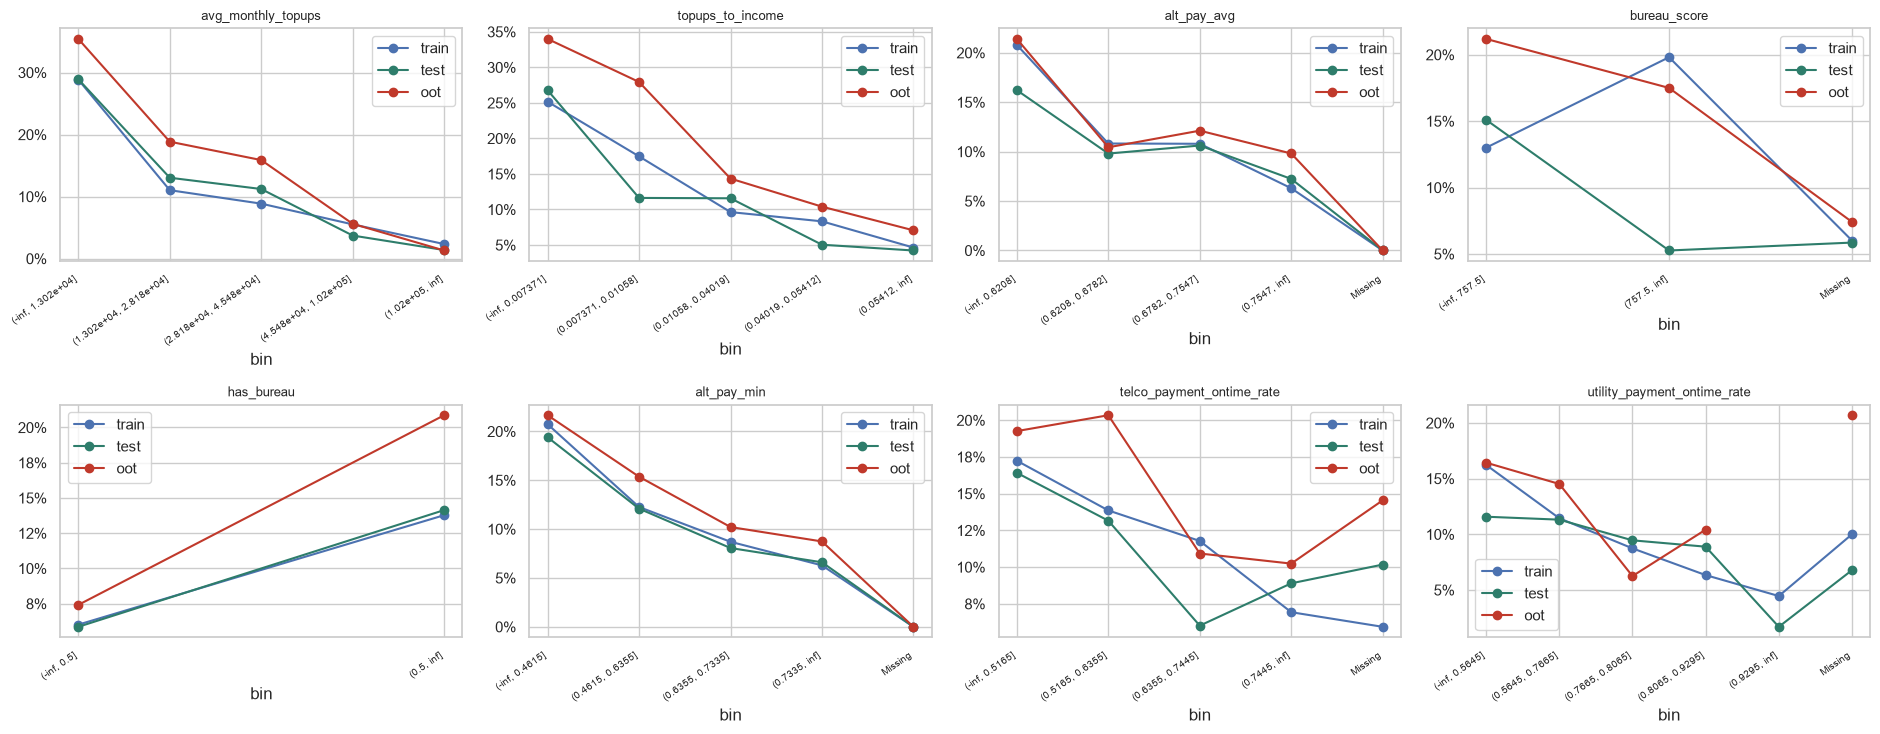

In [45]:
def tasa_por_bin(var):
    b = binners[var]
    return pd.DataFrame({n: d.groupby(b.bins(d[var]).values)["default"].mean()
                         for n, d in [("train", train), ("test", test), ("oot", oot)]}).loc[b.table_.index]

fig, axes = plt.subplots(2, 4, figsize=(19, 7.5))
for ax, v in zip(axes.ravel(), ivs.index[:8]):
    t = tasa_por_bin(v)
    t.plot(ax=ax, marker="o", color=["#4C72B0", "#2E7D6B", "#C0392B"])
    ax.set_xticks(range(len(t))); ax.set_xticklabels(t.index, rotation=35, fontsize=7, ha="right")
    ax.set_title(v, fontsize=9)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
plt.tight_layout(); plt.show()

### Hallazgos – estabilidad de variables, binning e IV

**CSI (7.2)**
- Entre train y test todas las variables son estables (CSI < 0,04): la partición aleatoria
  produce muestras equivalentes.
- En OOT hay **cambio significativo sólo en los datos alternativos de pago**: utility
  (0,80), `alt_pay_avg` (0,54), `alt_pay_min` (0,36) y telco (0,29). Es el quiebre detectado
  en el EDA (5.8). Todas las demás variables son estables (CSI < 0,03).

**IV (8.1)**
- **Fuertes:** recargas (0,49) y recargas/ingreso (0,31).
- **Medias:** `alt_pay_avg` (0,23), `bureau_score` (0,22), `has_bureau` (0,20),
  `alt_pay_min` (0,17), telco y utility (0,15 cada una).
- **Débiles:** P2P (0,09), monto solicitado, antigüedad, engagement, ingreso, edad, etc.
- **No predictivas:** `flag_age_18`, `product_type`, `n_alt_missing` y `monto_bono_referidos`
  (IV ≈ 0; el árbol ni siquiera encontró un corte).
- Combinar utility y telco en `alt_pay_avg` aumenta el IV (0,23) frente a cada fuente
  por separado (0,15), coherente con que miden comportamientos distintos (ρ ≈ 0,06).

**Detalle de bins (8.2)**
- Las tendencias son monótonas y con sentido de negocio: en recargas la tasa de default
  baja de 28,9 % (< 13 mil) a 2,4 % (> 102 mil).
- **El IV de `bureau_score` es engañoso:** proviene casi todo del bin "Missing"
  (= thin-file, 6,0 % de default). Dentro de quienes tienen score, el riesgo es *mayor*
  en scores altos (19,8 % vs 13,0 %), al revés de lo esperado. Lo que discrimina es
  *tener o no* buró, y eso ya lo captura `has_bureau`. → **Se excluye `bureau_score`.**
- **Política de nulos:** el bin "Missing" de `alt_pay_avg` tiene sólo 11 casos y 0 malos;
  su WoE empírico daría el mejor puntaje a quien no reporta datos. Se le asignó el WoE
  del bin más riesgoso (0,91). Los "Missing" de utility y telco (~6 %) conservan su WoE.

**Estabilidad por bin (8.3)**
- **Estables:** recargas, recargas/ingreso, `alt_pay_avg`, `alt_pay_min` y `has_bureau`
  mantienen la misma forma en train, test y OOT; en OOT la curva se desplaza hacia arriba
  (más riesgo en todos los bins) sin cambiar el orden.
- **Inestables:** `bureau_score` (el bin alto pasa de 19,8 % en train a 5 % en test),
  telco y utility por separado (en OOT algunos bins casi se vacían, p. ej. utility > 0,93).
  Refuerza usar el indicador combinado y excluir el score de buró.

## 9. Selección de variables
### 9.1 Forward selection con validación cruzada
En la siguiente celda se seleccionan las variables del modelo en tres pasos:
1. **Filtro:** IV ≥ 0,02, excluyendo `bureau_score` (su señal es el nulo estructural, ya
   representado por `has_bureau`).
2. **Forward selection:** en cada paso se agrega la variable que más aumenta la AUC
   promedio en **validación cruzada estratificada de 5 folds dentro de train**, descartando
   candidatas con correlación > 0,6 (en escala WoE) con alguna ya seleccionada.
3. **Parada:** cuando la ganancia de AUC es < 0,005. El error estándar de la AUC-CV es
   ≈ 0,016 (desviación ≈ 0,035 / √5); ganancias menores a un tercio de ese valor son
   indistinguibles de ruido y sólo agregarían complejidad.

In [46]:
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression

EXCLUIR = {"bureau_score"}
pool = [c for c in ivs.index if ivs.loc[c, "iv"] >= 0.02 and c not in EXCLUIR]
print("Pool tras filtro IV:", pool)

Wtr = woe_transform(train, binners)
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)

def cv_auc(cols):
    sc = []
    for a, b in skf.split(Wtr, train["default"]):
        m = LogisticRegression(C=1e6, max_iter=1000).fit(Wtr.iloc[a][cols], train["default"].iloc[a])
        sc.append(auc(train["default"].iloc[b], m.predict_proba(Wtr.iloc[b][cols])[:, 1]))
    return np.mean(sc), np.std(sc)

GANANCIA_MIN = 0.005
seleccionadas, camino, mejor = [], [], 0
while True:
    candidatas = []
    for c in [p for p in pool if p not in seleccionadas]:
        if seleccionadas and Wtr[seleccionadas + [c]].corr().loc[c, seleccionadas].abs().max() > 0.6:
            continue
        candidatas.append((cv_auc(seleccionadas + [c])[0], c))
    if not candidatas:
        break
    score, c = max(candidatas)
    if score - mejor < GANANCIA_MIN:
        break
    seleccionadas.append(c); mejor = score
    camino.append({"paso": len(seleccionadas), "variable_agregada": c,
                   "AUC_CV": score, "std": cv_auc(seleccionadas)[1]})

display(pd.DataFrame(camino).round(4))
print("Variables seleccionadas:", seleccionadas)

Pool tras filtro IV: ['avg_monthly_topups', 'topups_to_income', 'alt_pay_avg', 'has_bureau', 'alt_pay_min', 'telco_payment_ontime_rate', 'utility_payment_ontime_rate', 'pct_p2p_transfers', 'requested_amount_fix', 'app_tenure_months', 'req_to_income', 'tx_per_tenure', 'digital_engagement_score', 'device_price_tier', 'income', 'age', 'num_transactions_last_90d']


,paso,variable_agregada,AUC_CV,std
0,1,avg_monthly_topups,0.6809,0.0379
1,2,has_bureau,0.7323,0.0381
2,3,alt_pay_avg,0.7663,0.0483
3,4,pct_p2p_transfers,0.7767,0.0422
4,5,digital_engagement_score,0.7821,0.0400


Variables seleccionadas: ['avg_monthly_topups', 'has_bureau', 'alt_pay_avg', 'pct_p2p_transfers', 'digital_engagement_score']


### 9.2 Sensibilidad al tamaño del modelo
En la siguiente celda se verifica, sólo como diagnóstico, qué pasaría si se siguiera
agregando variables hasta llegar a 9. Para cada tamaño se reporta la AUC del modelo en
test y OOT y la AUC univariada de la última variable agregada. Si las variables extra no
mejoran fuera de muestra (o su AUC univariada es < 0,5, es decir, invierten su relación
con el riesgo), confirma que el criterio de parada evita el sobreajuste.

In [47]:
extra, mejor_tmp = list(seleccionadas), mejor
while len(extra) < 9:
    cand = [(cv_auc(extra + [c])[0], c) for c in pool if c not in extra
            and Wtr[extra + [c]].corr().loc[c, extra].abs().max() <= 0.6]
    if not cand:
        break
    extra.append(max(cand)[1])

filas = []
for k in range(1, len(extra) + 1):
    f = extra[:k]
    m = LogisticRegression(C=1e6, max_iter=1000).fit(Wtr[f], train["default"])
    r = {"n_vars": k, "ultima_variable": f[-1], "en_modelo": k <= len(seleccionadas)}
    for n, d in [("test", test), ("oot", oot)]:
        p = m.predict_proba(woe_transform(d, {c: binners[c] for c in f}))[:, 1]
        r[f"AUC_{n}"] = auc(d.default, p)
        r[f"AUC_univ_{n}"] = auc(d.default, binners[f[-1]].transform(d[f[-1]]))
    filas.append(r)
pd.DataFrame(filas).set_index("n_vars").round(4)

,ultima_variable,en_modelo,AUC_test,AUC_univ_test,AUC_oot,AUC_univ_oot
n_vars,,,,,,
1,avg_monthly_topups,True,0.7197,0.7197,0.7099,0.7099
2,has_bureau,True,0.7573,0.6186,0.7607,0.6417
3,alt_pay_avg,True,0.7805,0.5795,0.7834,0.5922
4,pct_p2p_transfers,True,0.7653,0.5240,0.7823,0.5230
5,digital_engagement_score,True,0.7716,0.5487,0.7856,0.5461
6,requested_amount_fix,False,0.7469,0.4784,0.7823,0.5038
7,income,False,0.7558,0.5813,0.7882,0.5646
8,device_price_tier,False,0.7585,0.5161,0.7826,0.4649
9,utility_payment_ontime_rate,False,0.7558,0.5624,0.7803,0.5529


### 9.3 Coeficientes, significancia y multicolinealidad
En la siguiente celda se ajusta una regresión logística con `statsmodels` sobre las
variables seleccionadas (en escala WoE) para revisar:
- **Signo:** con WoE = ln(%malos/%buenos) todos los coeficientes deben ser positivos.
- **Significancia:** p-valor de cada coeficiente.
- **Multicolinealidad:** VIF (< 2,5 es aceptable) y correlación entre variables WoE.

,coef,std_err,p_value,VIF,IV
const,-2.2699,0.0856,0.0000,NaN,NaN
avg_monthly_topups,1.0679,0.1103,0.0000,1.0021,0.4916
has_bureau,1.0082,0.1810,0.0000,1.0028,0.2029
alt_pay_avg,1.0497,0.1605,0.0000,1.0019,0.2293
pct_p2p_transfers,1.1180,0.3177,0.0004,1.0029,0.0881
digital_engagement_score,1.0757,0.4003,0.0072,1.0020,0.0387


Coeficientes positivos: True | p-valor máx: 0.0072 | VIF máx: 1.0


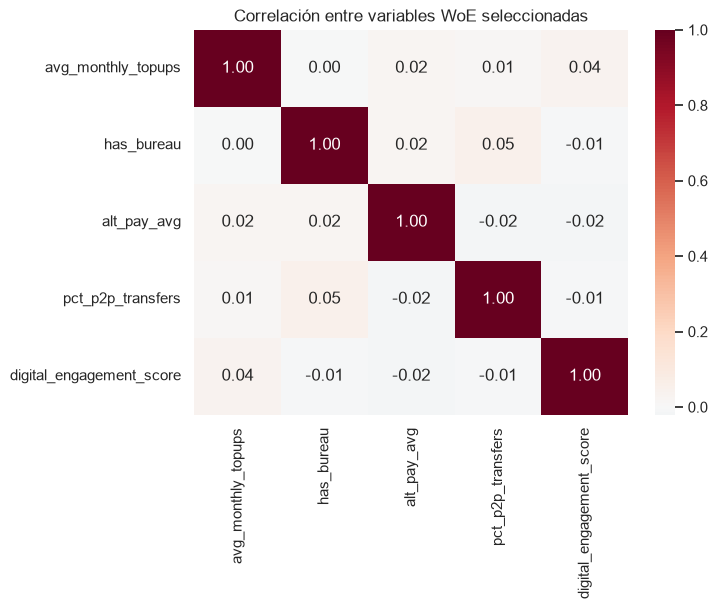

In [48]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_sm = sm.add_constant(Wtr[seleccionadas])
logit = sm.Logit(train["default"], X_sm).fit(disp=False)
coef = pd.DataFrame({"coef": logit.params, "std_err": logit.bse, "p_value": logit.pvalues})
coef["VIF"] = [np.nan] + [variance_inflation_factor(X_sm.values, i) for i in range(1, X_sm.shape[1])]
coef["IV"] = [np.nan] + [binners[c].iv_ for c in seleccionadas]
display(coef.round(4))
print("Coeficientes positivos:", (coef.coef[1:] > 0).all(),
      "| p-valor máx:", round(coef.p_value[1:].max(), 4), "| VIF máx:", round(coef.VIF.max(), 2))

plt.figure(figsize=(7, 5))
sns.heatmap(Wtr[seleccionadas].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlación entre variables WoE seleccionadas"); plt.show()

### Hallazgos – selección de variables

- **Variables seleccionadas (5):** `avg_monthly_topups`, `has_bureau`, `alt_pay_avg`,
  `pct_p2p_transfers` y `digital_engagement_score`. AUC-CV en train: 0,68 con una variable
  → 0,78 con las cinco.
- **Validación estadística:** todos los coeficientes son positivos (coherente con
  WoE = ln(%malos/%buenos)), significativos (p < 0,01) y sin multicolinealidad
  (VIF ≈ 1,0; correlaciones entre variables WoE |ρ| ≤ 0,05). Cada variable aporta
  información independiente.
- **Lectura de negocio:**
  - `avg_monthly_topups`: **capacidad / liquidez observada** (flujo de caja real).
  - `has_bureau`: **endeudamiento previo**; en esta población tener buró aumenta el riesgo.
  - `alt_pay_avg`: **hábito de pago** en servicios públicos y telco.
  - `pct_p2p_transfers`: **dependencia de transferencias entre personas** (ingresos
    informales o préstamos entre conocidos); a mayor % P2P, más riesgo.
  - `digital_engagement_score`: aporte **marginal** (IV 0,04) y patrón no monótono (más
    riesgo en uso medio). Es estable y su AUC univariada es igual en test y OOT (≈ 0,55),
    por lo que el procedimiento la retiene; se marca para **validar su interpretación con
    negocio** antes de producción (primera candidata a salir si no hay explicación).
- **Sensibilidad (9.2):** las variables que el criterio de parada deja fuera no mejoran
  fuera de muestra: con 6 a 9 variables la AUC de test cae (0,77 → 0,75–0,76) y en OOT
  se mantiene igual (≈ 0,78). Algunas tienen AUC univariada < 0,5 en test u OOT
  (`requested_amount_fix` 0,48; `device_price_tier` 0,46): **invierten su relación con el
  riesgo** fuera de train, señal típica de sobreajuste. Se prefiere el modelo parsimonioso.

## 10. Modelamiento
### 10.1 Modelo campeón: regresión logística sobre WoE
En la siguiente celda se entrena el modelo campeón: regresión logística sobre las variables
WoE seleccionadas (sin regularización, C muy alto, porque las variables ya son pocas y no
colineales). Se elige como campeón por:
- **Explicabilidad:** cada atributo suma o resta puntos y permite dar razones de rechazo,
  algo exigido en originación de crédito.
- **Estabilidad con muestras pequeñas** (≈ 200 malos en train).
- **Facilidad de implementación y monitoreo** (scorecard).  
Se calcula la PD predicha para train, test y OOT.

In [53]:
campeon = LogisticRegression(C=1e6, max_iter=1000).fit(Wtr[seleccionadas], train["default"])
binners_modelo = {c: binners[c] for c in seleccionadas}

def predecir_campeon(d):
    return campeon.predict_proba(woe_transform(d, binners_modelo))[:, 1]

for d in (train, test, oot):
    d["pd_lr"] = predecir_campeon(d)
print("Intercepto:", round(campeon.intercept_[0], 4))
print("Coeficientes:", {k: round(float(v), 4) for k, v in zip(seleccionadas, campeon.coef_[0])})

Intercepto: -2.27
Coeficientes: {'avg_monthly_topups': 1.0663, 'has_bureau': 1.0063, 'alt_pay_avg': 1.0497, 'pct_p2p_transfers': 1.1276, 'digital_engagement_score': 1.0801}


### 10.2 Retador 1: LightGBM
En la siguiente celda se entrena un modelo retador de *gradient boosting* (LightGBM) sobre
las variables crudas, para verificar si un modelo no lineal captura señal que la regresión
pierde. Para controlar el sobreajuste:
- Árboles pequeños (4 u 8 hojas), mínimo de casos por hoja y regularización L2.
- **Restricciones monótonas** en las variables con dirección clara (recargas, pagos e
  ingreso reducen el riesgo; tener buró lo aumenta).
- Hiperparámetros elegidos por **validación cruzada de 5 folds dentro de train**.

In [50]:
import lightgbm as lgb

VARS_GBM = ["avg_monthly_topups", "utility_payment_ontime_rate", "telco_payment_ontime_rate", "has_bureau",
            "digital_engagement_score", "income", "pct_p2p_transfers", "app_tenure_months", "age",
            "requested_amount_fix", "device_price_tier", "num_transactions_last_90d", "topups_to_income"]
MONO_GBM = [-1, -1, -1, 1, 0, -1, 0, 0, 0, 0, 0, 0, -1]

grilla = [dict(num_leaves=nl, min_child_samples=mcs, learning_rate=0.03, n_estimators=ne)
          for nl in [4, 8] for mcs in [40, 80] for ne in [150, 300]]
res = []
for g in grilla:
    sc = []
    for a, b in skf.split(train, train["default"]):
        m = lgb.LGBMClassifier(**g, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5,
                               monotone_constraints=MONO_GBM, random_state=SEED, verbose=-1)
        m.fit(train.iloc[a][VARS_GBM], train["default"].iloc[a])
        sc.append(auc(train["default"].iloc[b], m.predict_proba(train.iloc[b][VARS_GBM])[:, 1]))
    res.append({**g, "AUC_CV": np.mean(sc)})
res = pd.DataFrame(res).sort_values("AUC_CV", ascending=False)
display(res.head().round(4))

mejor_g = {k: (int(v) if k != "learning_rate" else float(v))
           for k, v in res.iloc[0][["num_leaves", "min_child_samples", "learning_rate", "n_estimators"]].items()}
gbm = lgb.LGBMClassifier(**mejor_g, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5,
                         monotone_constraints=MONO_GBM, random_state=SEED, verbose=-1).fit(train[VARS_GBM], train["default"])
for d in (train, test, oot):
    d["pd_gbm"] = gbm.predict_proba(d[VARS_GBM])[:, 1]

imp = pd.Series(gbm.booster_.feature_importance("gain"), VARS_GBM).sort_values(ascending=False)
(imp / imp.sum()).to_frame("importancia_gain").round(4)

,num_leaves,min_child_samples,learning_rate,n_estimators,AUC_CV
6,8,80,0.03,150,0.7390
7,8,80,0.03,300,0.7363
4,8,40,0.03,150,0.7350
1,4,40,0.03,300,0.7337
3,4,80,0.03,300,0.7333


,importancia_gain
avg_monthly_topups,0.2507
utility_payment_ontime_rate,0.1365
telco_payment_ontime_rate,0.1077
has_bureau,0.1004
requested_amount_fix,0.0576
digital_engagement_score,0.0548
pct_p2p_transfers,0.0546
topups_to_income,0.0532
app_tenure_months,0.0527
income,0.0522


### 10.3 Retador 2: modelos segmentados por buró
En la siguiente celda se entrena un retador segmentado: una scorecard independiente para
clientes **sin buró** y otra para clientes **con buró**, con las mismas variables (excepto
`has_bureau`) y binning reajustado dentro de cada segmento. Responde a la pregunta de si
las dos poblaciones necesitan modelos distintos o basta un modelo único con el indicador.

In [51]:
modelos_seg = {}
vars_seg_modelo = [c for c in seleccionadas if c != "has_bureau"]
for flag in [0, 1]:
    tr_s = train[train.has_bureau == flag]
    b_s = ajustar_binners(tr_s, tr_s["default"], vars_seg_modelo, monotonic=MONO, max_bins=5, min_bin_pct=0.05)
    if "digital_engagement_score" in vars_seg_modelo:
        b_s["digital_engagement_score"] = WoEBinner(max_bins=3, min_bin_pct=0.10, monotonic=None).fit(
            tr_s["digital_engagement_score"], tr_s["default"])
    m_s = LogisticRegression(C=1e6, max_iter=1000).fit(woe_transform(tr_s, b_s), tr_s["default"])
    modelos_seg[flag] = (b_s, m_s)

def predecir_segmentado(d):
    out = np.zeros(len(d))
    for flag, (b_s, m_s) in modelos_seg.items():
        mask = (d.has_bureau == flag).values
        out[mask] = m_s.predict_proba(woe_transform(d[mask], b_s))[:, 1]
    return out

for d in (train, test, oot):
    d["pd_seg"] = predecir_segmentado(d)

### 10.4 Comparación campeón vs. retadores
En la siguiente celda se comparan los tres modelos en train, test y OOT con AUC y KS.
También se calcula la brecha de AUC entre train y test: una brecha grande indica
sobreajuste (el modelo memoriza train y no generaliza).

In [52]:
filas_cmp = []
for modelo, col in [("LR-WoE (campeón)", "pd_lr"), ("LightGBM", "pd_gbm"), ("LR segmentada", "pd_seg")]:
    for n, d in [("train", train), ("test", test), ("oot", oot)]:
        filas_cmp.append({"modelo": modelo, "split": n, "AUC": auc(d.default, d[col]), "KS": ks(d.default, d[col])})
cmp = pd.DataFrame(filas_cmp).pivot(index="modelo", columns="split", values=["AUC", "KS"])
cmp[("AUC", "brecha_train_test")] = cmp[("AUC", "train")] - cmp[("AUC", "test")]
cmp.round(4)

AUC                      KS                  \
split                oot    test   train     oot    test   train   
modelo                                                             
LR segmentada     0.7374  0.7367  0.8087  0.3509  0.3666  0.4866   
LR-WoE (campeón)  0.7856  0.7716  0.7852  0.4557  0.4438  0.4474   
LightGBM          0.7751  0.7587  0.8667  0.4567  0.4330  0.5642   

                               AUC  
split            brecha_train_test  
modelo                              
LR segmentada               0.0720  
LR-WoE (campeón)            0.0136  
LightGBM                    0.1080

### Hallazgos – campeón vs. retadores

| Modelo | AUC train | AUC test | AUC OOT | KS test | KS OOT | Brecha train–test |
|---|---|---|---|---|---|---|
| **LR-WoE (campeón)** | 0,785 | **0,772** | **0,786** | 0,444 | 0,456 | **0,014** |
| LightGBM | 0,867 | 0,759 | 0,775 | 0,433 | 0,457 | 0,108 |
| LR segmentada | 0,809 | 0,737 | 0,737 | 0,367 | 0,351 | 0,072 |

- **LightGBM sobreajusta:** AUC 0,87 en train pero 0,76 en test (brecha ≈ 0,11 vs 0,01 del
  campeón), sin superar al campeón en test ni en OOT. Su importancia de variables confirma
  la señal encontrada: recargas, pagos alternativos y buró concentran ≈ 60 % de la ganancia.
  No hay evidencia de relaciones no lineales relevantes que la regresión esté perdiendo.
- **Los modelos segmentados rinden peor:** al partir la muestra cada modelo tiene la mitad de
  los malos (≈ 70 y 130), el binning se vuelve más ruidoso y se sobreajusta. Confirma lo visto
  en el EDA: las pendientes son similares en ambos segmentos y basta **un modelo único con
  `has_bureau`** como variable.
- **Se mantiene la regresión logística sobre WoE como modelo final:** mejor desempeño fuera
  de muestra, brecha mínima, interpretable y simple de implementar.

## 11. Validación del modelo campeón
### 11.1 Discriminación con intervalos de confianza
En la siguiente celda se calculan las métricas de validación en cada muestra:
- **AUC y Gini** (Gini = 2·AUC − 1) y **KS**, con intervalos de confianza del 95 % por
  *bootstrap* (1.000 remuestreos), para dimensionar la incertidumbre dada la muestra pequeña.
- **Brier score:** error cuadrático medio de la probabilidad (calibración + discriminación).
- **PD media vs. tasa de default observada.**

In [54]:
from sklearn.metrics import brier_score_loss

filas_val = []
for n, d in [("train", train), ("test", test), ("oot", oot)]:
    lo, hi = bootstrap_ci(d.default, d.pd_lr, auc)
    klo, khi = bootstrap_ci(d.default, d.pd_lr, ks)
    filas_val.append({"split": n, "n": len(d), "tasa_default": d.default.mean(),
                      "AUC": auc(d.default, d.pd_lr), "AUC_IC95": f"[{lo:.3f}, {hi:.3f}]",
                      "Gini": gini(d.default, d.pd_lr), "KS": ks(d.default, d.pd_lr),
                      "KS_IC95": f"[{klo:.3f}, {khi:.3f}]",
                      "Brier": brier_score_loss(d.default, d.pd_lr), "PD_media": d.pd_lr.mean()})
val = pd.DataFrame(filas_val).set_index("split")
val.round(4)

,n,tasa_default,AUC,AUC_IC95,Gini,KS,KS_IC95,Brier,PD_media
split,,,,,,,,,
train,2060,0.0951,0.7852,"[0.754, 0.816]",0.5704,0.4474,"[0.397, 0.515]",0.0775,0.0951
test,884,0.0950,0.7716,"[0.718, 0.822]",0.5432,0.4438,"[0.368, 0.554]",0.0786,0.0937
oot,986,0.1369,0.7856,"[0.747, 0.822]",0.5712,0.4557,"[0.397, 0.540]",0.1029,0.1234


### 11.2 Curvas ROC y KS
En la siguiente celda se grafican las curvas ROC de las tres muestras y las curvas de KS
(distribución acumulada de la PD en buenos y malos) para test y OOT. La línea punteada
marca el punto de máxima separación.

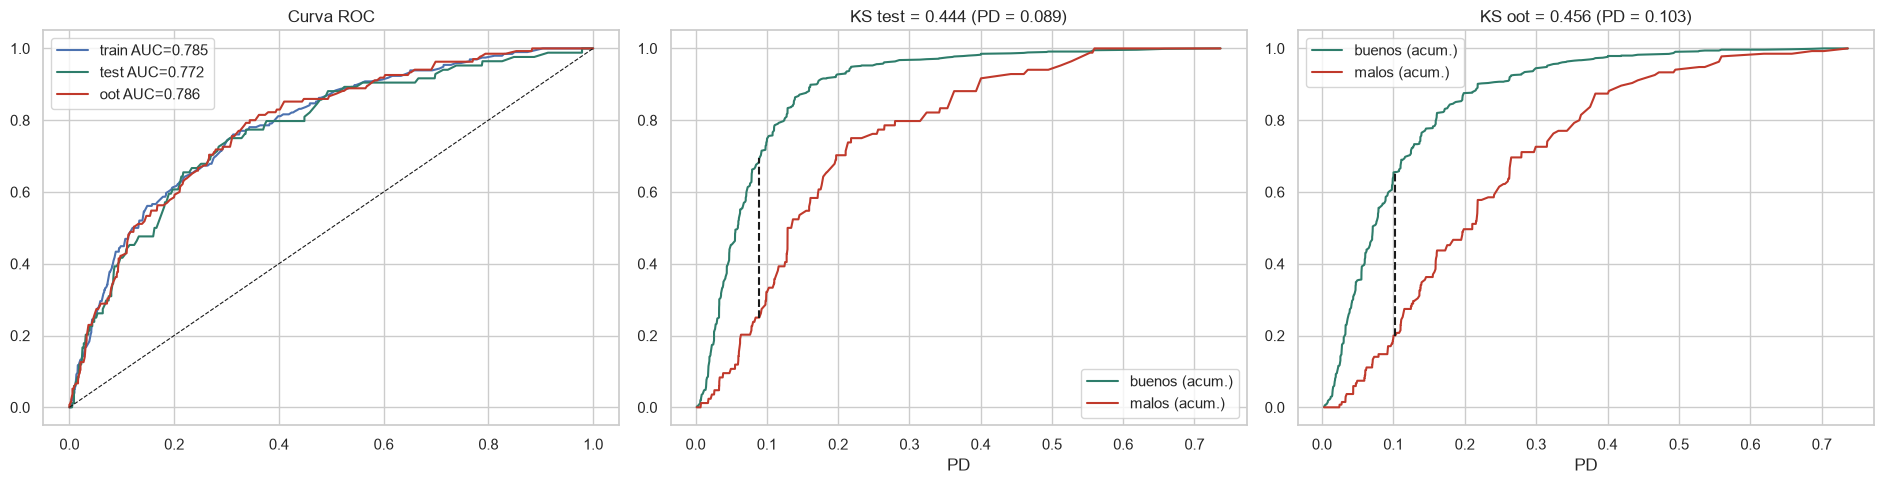

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for n, d, col in [("train", train, "#4C72B0"), ("test", test, "#2E7D6B"), ("oot", oot, "#C0392B")]:
    fpr, tpr, _ = roc_curve(d.default, d.pd_lr)
    axes[0].plot(fpr, tpr, label=f"{n} AUC={auc(d.default, d.pd_lr):.3f}", color=col)
axes[0].plot([0, 1], [0, 1], "k--", lw=.8); axes[0].set_title("Curva ROC"); axes[0].legend()

for ax, (n, d) in zip(axes[1:], [("test", test), ("oot", oot)]):
    s = np.sort(d.pd_lr.unique())
    acum_malos = np.array([(d.loc[d.default == 1, "pd_lr"] <= t).mean() for t in s])
    acum_buenos = np.array([(d.loc[d.default == 0, "pd_lr"] <= t).mean() for t in s])
    i = np.argmax(np.abs(acum_buenos - acum_malos))
    ax.plot(s, acum_buenos, label="buenos (acum.)", color="#2E7D6B")
    ax.plot(s, acum_malos, label="malos (acum.)", color="#C0392B")
    ax.vlines(s[i], acum_malos[i], acum_buenos[i], color="k", ls="--")
    ax.set_title(f"KS {n} = {abs(acum_buenos[i] - acum_malos[i]):.3f} (PD = {s[i]:.3f})")
    ax.set_xlabel("PD"); ax.legend()
plt.tight_layout(); plt.show()

### 11.3 Ordenamiento del riesgo por deciles
En la siguiente celda se ordena cada muestra por PD (decil 1 = más riesgoso) y se calcula,
por decil, la tasa de default, el % acumulado de malos y buenos capturados, el KS y el
*lift* (cuántas veces la tasa del decil supera la tasa promedio).

In [56]:
for n, d in [("test", test), ("oot", oot)]:
    print(f"=== {n}")
    t = tabla_deciles(d.default, d.pd_lr)
    display(t[["n", "malos", "tasa_malos", "pct_malos_acum", "pct_buenos_acum", "ks", "lift"]].round(4))
    print(f"% de malos en el 30 % más riesgoso: {t.pct_malos_acum.iloc[2]:.1%} | "
          f"lift decil 1: {t.lift.iloc[0]:.2f}")

=== test


,n,malos,tasa_malos,pct_malos_acum,pct_buenos_acum,ks,lift
decil,,,,,,,
1,89,26,0.2921,0.3095,0.0788,0.2308,3.0744
2,88,17,0.1932,0.5119,0.1675,0.3444,2.0330
3,88,14,0.1591,0.6786,0.2600,0.4186,1.6742
4,89,8,0.0899,0.7738,0.3612,0.4126,0.9460
5,88,5,0.0568,0.8333,0.4650,0.3683,0.5979
6,88,6,0.0682,0.9048,0.5675,0.3373,0.7175
7,89,1,0.0112,0.9167,0.6775,0.2392,0.1182
8,88,3,0.0341,0.9524,0.7837,0.1686,0.3588
9,88,2,0.0227,0.9762,0.8912,0.0849,0.2392


% de malos en el 30 % más riesgoso: 67.9% | lift decil 1: 3.07
=== oot


,n,malos,tasa_malos,pct_malos_acum,pct_buenos_acum,ks,lift
decil,,,,,,,
1,99,39,0.3939,0.2889,0.0705,0.2184,2.8772
2,99,33,0.3333,0.5333,0.1481,0.3853,2.4346
3,98,17,0.1735,0.6593,0.2432,0.4160,1.2670
4,99,18,0.1818,0.7926,0.3384,0.4542,1.3279
5,98,8,0.0816,0.8519,0.4442,0.4077,0.5962
6,99,5,0.0505,0.8889,0.5546,0.3342,0.3689
7,98,7,0.0714,0.9407,0.6616,0.2792,0.5217
8,99,4,0.0404,0.9704,0.7732,0.1972,0.2951
9,98,4,0.0408,1.0000,0.8837,0.1163,0.2981


% de malos en el 30 % más riesgoso: 65.9% | lift decil 1: 2.88


### 11.4 Calibración
En la siguiente celda se evalúa la calibración: si la PD predicha coincide con la tasa de
default observada. Se agrupa cada muestra en deciles de PD y se grafica la PD media contra
la tasa observada (la diagonal es calibración perfecta). También se calcula el cociente
observado / predicho a nivel global.

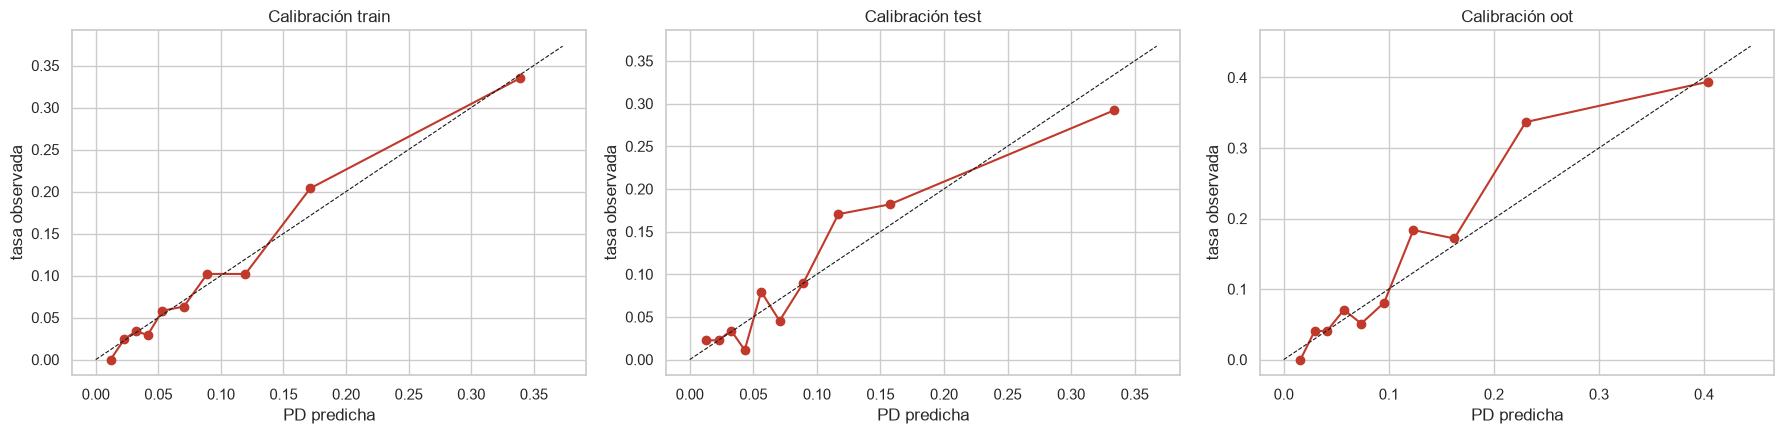

,PD_media,tasa_observada,observado/predicho
split,,,
train,0.0951,0.0951,1.0001
test,0.0937,0.0950,1.0145
oot,0.1234,0.1369,1.1100


In [57]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
filas_cal = []
for ax, (n, d) in zip(axes, [("train", train), ("test", test), ("oot", oot)]):
    q = pd.qcut(d.pd_lr.rank(method="first"), 10, labels=False)
    c = d.groupby(q).agg(pd_media=("pd_lr", "mean"), tasa_obs=("default", "mean"))
    lim = c.max().max() * 1.1
    ax.plot(c.pd_media, c.tasa_obs, "o-", color="#C0392B")
    ax.plot([0, lim], [0, lim], "k--", lw=.8)
    ax.set_title(f"Calibración {n}"); ax.set_xlabel("PD predicha"); ax.set_ylabel("tasa observada")
    filas_cal.append({"split": n, "PD_media": d.pd_lr.mean(), "tasa_observada": d.default.mean(),
                      "observado/predicho": d.default.mean() / d.pd_lr.mean()})
plt.tight_layout(); plt.show()
pd.DataFrame(filas_cal).set_index("split").round(4)

### 11.5 AUC y KS por variable en validación
En la siguiente celda se calcula la AUC y el KS de cada variable del modelo (en su escala
WoE) en test y OOT, junto con los del modelo completo. Muestra cuánto aporta cada variable
por separado y cuánto se gana al combinarlas.

In [58]:
filas_var = []
for c in seleccionadas:
    for n, d in [("test", test), ("oot", oot)]:
        w = binners[c].transform(d[c])
        filas_var.append({"variable": c, "split": n, "AUC": auc(d.default, w), "KS": ks(d.default, w)})
for n, d in [("test", test), ("oot", oot)]:
    filas_var.append({"variable": "MODELO", "split": n, "AUC": auc(d.default, d.pd_lr), "KS": ks(d.default, d.pd_lr)})
pd.DataFrame(filas_var).pivot(index="variable", columns="split", values=["AUC", "KS"]).round(4)

AUC              KS        
split                        oot    test     oot    test
variable                                                
MODELO                    0.7856  0.7716  0.4557  0.4438
alt_pay_avg               0.5922  0.5795  0.1746  0.1315
avg_monthly_topups        0.7099  0.7197  0.3274  0.3421
digital_engagement_score  0.5461  0.5487  0.0901  0.0827
has_bureau                0.6417  0.6186  0.2834  0.2373
pct_p2p_transfers         0.5230  0.5240  0.0389  0.0542

### 11.6 Estabilidad del score (PSI) y de las variables del modelo
En la siguiente celda se calcula el PSI de la PD entre muestras (referencia = train, cortes por
deciles) y el CSI sobre los **bins que usa el modelo** (lo que realmente mueve el score).
Se grafica la distribución de la PD por muestra y se detalla cómo cambia la distribución
de `alt_pay_avg` por bin, la variable con mayor deriva.

,PSI,lectura
train vs test,0.0177,Estable
train vs OOT,0.1092,Cambio moderado
test vs OOT,0.1118,Cambio moderado


,CSI_test,CSI_oot,lectura_oot
avg_monthly_topups,0.0030,0.0065,Estable
has_bureau,0.0005,0.0010,Estable
alt_pay_avg,0.0065,0.3363,Cambio significativo
pct_p2p_transfers,0.0043,0.0006,Estable
digital_engagement_score,0.0007,0.0025,Estable


,train,test,oot
bin,,,
"(-inf, 0.6208]",0.1097,0.1256,0.2748
"(0.6208, 0.6782]",0.1301,0.1154,0.1846
"(0.6782, 0.7547]",0.2383,0.2557,0.2677
"(0.7547, inf]",0.5165,0.5000,0.2688
Missing,0.0053,0.0034,0.0041


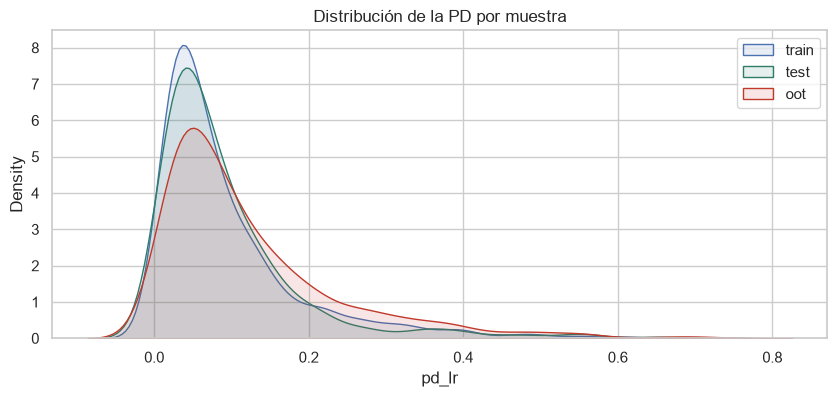

In [59]:
psi_test, _ = psi(train.pd_lr, test.pd_lr, return_table=True)
psi_oot, tab_oot = psi(train.pd_lr, oot.pd_lr, return_table=True)
tabla_psi = pd.DataFrame({"PSI": [psi_test, psi_oot, psi(test.pd_lr, oot.pd_lr)]},
                         index=["train vs test", "train vs OOT", "test vs OOT"])
tabla_psi["lectura"] = tabla_psi.PSI.map(lectura_psi)
display(tabla_psi.round(4))

csi_modelo = pd.DataFrame({c: {"CSI_test": psi_categorica(binners[c].bins(train[c]), binners[c].bins(test[c])),
                               "CSI_oot": psi_categorica(binners[c].bins(train[c]), binners[c].bins(oot[c]))}
                           for c in seleccionadas}).T
csi_modelo["lectura_oot"] = csi_modelo.CSI_oot.map(lectura_psi)
display(csi_modelo.round(4))

dist_alt = pd.DataFrame({n: binners["alt_pay_avg"].bins(d["alt_pay_avg"]).value_counts(normalize=True)
                         for n, d in [("train", train), ("test", test), ("oot", oot)]})
display(dist_alt.loc[binners["alt_pay_avg"].table_.index].round(4))

fig, ax = plt.subplots(figsize=(10, 4))
for n, d, col in [("train", train, "#4C72B0"), ("test", test, "#2E7D6B"), ("oot", oot, "#C0392B")]:
    sns.kdeplot(d.pd_lr, ax=ax, label=n, color=col, fill=True, alpha=.12)
ax.set_title("Distribución de la PD por muestra"); ax.legend(); plt.show()

### 11.7 Desempeño por segmento de buró
En la siguiente celda se evalúa el modelo por separado en clientes sin buró (población
objetivo del piloto) y con buró: tasa de default, PD media, AUC y KS en test y OOT.

In [60]:
filas_seg = []
for n, d in [("test", test), ("oot", oot)]:
    for flag, etiqueta in [(0, "Sin buró"), (1, "Con buró")]:
        s = d[d.has_bureau == flag]
        filas_seg.append({"split": n, "segmento": etiqueta, "n": len(s), "tasa_default": s.default.mean(),
                          "PD_media": s.pd_lr.mean(), "AUC": auc(s.default, s.pd_lr), "KS": ks(s.default, s.pd_lr)})
desempeno_seg = pd.DataFrame(filas_seg).set_index(["split", "segmento"])
desempeno_seg.round(4)

n  tasa_default  PD_media     AUC      KS
split segmento                                             
test  Sin buró  495        0.0586    0.0621  0.7661  0.4360
      Con buró  389        0.1414    0.1338  0.7160  0.3530
oot   Sin buró  526        0.0741    0.0831  0.7886  0.4521
      Con buró  460        0.2087    0.1694  0.7291  0.3690

### Hallazgos – validación del modelo

**Discriminación (11.1–11.2)**

| Muestra | AUC (IC 95 %) | Gini | KS (IC 95 %) |
|---|---|---|---|
| Train | 0,785 [0,754–0,816] | 0,570 | 0,447 |
| Test | **0,772** [0,718–0,822] | 0,543 | **0,444** [0,368–0,554] |
| OOT | **0,786** [0,747–0,822] | 0,571 | **0,456** [0,397–0,540] |

- El modelo **generaliza**: la brecha train–test es de 0,014 y en OOT el AUC no se degrada,
  a pesar del cambio de población. Las curvas ROC de las tres muestras prácticamente se superponen.
- Los intervalos de confianza son anchos (± 0,05 en test) por el tamaño de muestra
  (84 malos en test), pero su límite inferior (≈ 0,72) sigue por encima de 0,70.

**Ordenamiento (11.3)**
- El 30 % más riesgoso concentra **≈ 2/3 de los malos** (67,9 % test, 65,9 % OOT) y el primer
  decil tiene un *lift* ≈ 3 (tasa de default del 29 % en test y 39 % en OOT).
- En test la tasa de default es monótona en los 5 deciles más riesgosos. Las inversiones
  que aparecen son entre deciles adyacentes con muy pocos malos (≤ 18 por decil): ruido
  muestral, no cambios de tendencia.

**Calibración (11.4)**
- Train y test están bien calibrados (observado/predicho 1,00 y 1,01).
- En **OOT el modelo subestima el nivel de riesgo** (PD media 12,3 % vs 13,7 % observado,
  cociente 1,11), aunque sigue ordenando bien. Es el patrón de una deriva de nivel: se corrige
  **recalibrando el intercepto** al nivel reciente, sin reentrenar las pendientes.

**Aporte por variable (11.5)**
- La mejor variable sola (recargas) alcanza AUC 0,72 / KS 0,34 en test; el modelo combinado
  llega a 0,77 / 0,44 (≈ +5 pp de AUC), gracias a que las variables aportan información
  independiente. Las AUC por variable son casi iguales en test y OOT.

**Estabilidad (11.6)**
- PSI del score: train vs test **0,018 (estable)**; train vs OOT **0,109 (cambio moderado)**.
- El cambio viene casi todo de `alt_pay_avg` (CSI 0,34 en OOT): el % de clientes en el bin de
  peor pago pasa de 11 % a 27 % y el del mejor bin de 52 % a 27 %. Las otras cuatro variables
  son estables (CSI < 0,01).
- La distribución de la PD en OOT se desplaza hacia valores más altos, coherente con la mayor
  tasa de default observada.

**Por segmento (11.7)**
- El modelo ordena bien en ambos segmentos y **mejor en thin-file**, la población objetivo
  (AUC 0,77 en test y 0,79 en OOT, vs 0,72–0,73 con buró).
- La subestimación en OOT se concentra en clientes **con buró** (observado 20,9 % vs PD 16,9 %),
  el segmento donde más subió el default; en sin buró la diferencia es menor (7,4 % vs 8,3 %,
  incluso sobreestima ligeramente). La recalibración debe monitorearse por segmento.

## 12. Scorecard y estrategia de corte

### 12.1 Tabla de puntos (scorecard)
En la siguiente celda se convierte el modelo en un scorecard de puntos con el escalamiento
estándar de la industria: **600 puntos equivalen a odds de 30 buenos por 1 malo, y cada
20 puntos (PDO) se duplican las odds**. Mayor puntaje = menor riesgo. Para cada variable y
bin se calculan los puntos que aporta, de modo que el score total es la suma de los puntos
de los atributos del cliente.

In [61]:
PDO, BASE, ODDS = 20, 600, 30
factor = PDO / np.log(2)
offset = BASE - factor * np.log(ODDS)
b0, n_vars = campeon.intercept_[0], len(seleccionadas)

filas_sc = []
for c, beta in zip(seleccionadas, campeon.coef_[0]):
    for bin_, r in binners[c].table_.iterrows():
        puntos = -(beta * r.woe + b0 / n_vars) * factor + offset / n_vars
        filas_sc.append({"variable": c, "bin": bin_, "pct_poblacion": r.pct_n,
                         "tasa_malos_train": r.tasa_malos, "woe": r.woe, "puntos": round(puntos)})
scorecard = pd.DataFrame(filas_sc)
display(scorecard.round(4))

for d in (train, test, oot):
    d["score"] = (offset - factor * np.log(d.pd_lr / (1 - d.pd_lr))).round()
print("Rango del score en test:", test.score.min(), "–", test.score.max())

,variable,bin,pct_poblacion,tasa_malos_train,woe,puntos
0,avg_monthly_topups,"(-inf, 1.302e+04]",0.0976,0.2886,1.3437,72
1,avg_monthly_topups,"(1.302e+04, 2.818e+04]",0.2155,0.1104,0.1629,108
2,avg_monthly_topups,"(2.818e+04, 4.548e+04]",0.2354,0.0887,-0.0786,116
3,avg_monthly_topups,"(4.548e+04, 1.02e+05]",0.3689,0.0553,-0.5866,132
4,avg_monthly_topups,"(1.02e+05, inf]",0.0825,0.0235,-1.3699,156
5,has_bureau,"(-inf, 0.5]",0.5490,0.0601,-0.4947,128
6,has_bureau,"(0.5, inf]",0.4510,0.1378,0.4173,101
7,alt_pay_avg,"(-inf, 0.6208]",0.1097,0.2080,0.9116,86
8,alt_pay_avg,"(0.6208, 0.6782]",0.1301,0.1082,0.1469,109
9,alt_pay_avg,"(0.6782, 0.7547]",0.2383,0.1079,0.1374,109


Rango del score en test: 472.0 – 687.0


### 12.2 Curva estratégica: aprobación vs. riesgo
En la siguiente celda se simulan distintos puntos de corte sobre test + OOT (datos no usados
para entrenar): para cada score mínimo se calcula la tasa de aprobación, la tasa de default de
los aprobados y de los rechazados, y el % de malos que se evitaría. Se grafica la curva
aprobación vs. tasa de default de aprobados, frente a no usar modelo (aprobar todo).

,score_minimo,tasa_aprobacion,tasa_default_aprobados,tasa_default_rechazados,pct_malos_evitados
0,500,98.6%,11.2%,44.4%,5.5%
1,510,97.3%,10.9%,42.0%,9.6%
2,520,94.8%,9.8%,45.9%,20.5%
3,530,91.8%,9.3%,38.6%,26.9%
4,540,87.1%,8.0%,36.8%,40.6%
5,550,80.9%,7.0%,31.6%,51.6%
6,560,69.5%,5.4%,26.1%,68.0%
7,570,57.0%,3.8%,22.1%,81.3%
8,580,45.2%,3.7%,18.4%,85.8%
9,590,32.3%,2.6%,16.0%,92.7%


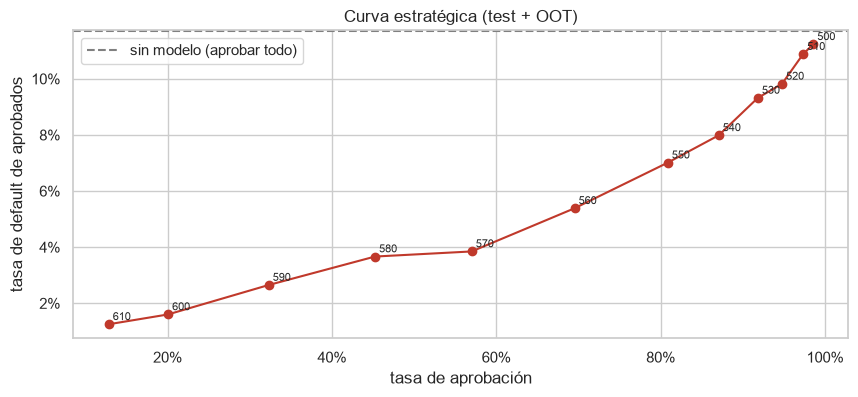

In [62]:
ref = pd.concat([test, oot])
filas_corte = []
for s in range(500, 620, 10):
    ap = ref[ref.score >= s]
    filas_corte.append({"score_minimo": s, "tasa_aprobacion": len(ap) / len(ref),
                        "tasa_default_aprobados": ap.default.mean(),
                        "tasa_default_rechazados": ref[ref.score < s].default.mean(),
                        "pct_malos_evitados": 1 - ap.default.sum() / ref.default.sum()})
cortes = pd.DataFrame(filas_corte)
display(cortes.style.format({c: "{:.1%}" for c in cortes.columns if c != "score_minimo"}))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(cortes.tasa_aprobacion, cortes.tasa_default_aprobados, "o-", color="#C0392B")
for _, r in cortes.iterrows():
    ax.annotate(int(r.score_minimo), (r.tasa_aprobacion, r.tasa_default_aprobados),
                fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.axhline(ref.default.mean(), ls="--", color="grey", label="sin modelo (aprobar todo)")
ax.set_xlabel("tasa de aprobación"); ax.set_ylabel("tasa de default de aprobados"); ax.legend()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Curva estratégica (test + OOT)"); plt.show()

## 13. Revisión de equidad
En la siguiente celda se audita el modelo por `sexo`, variable **excluida** del modelo por
ser protegida. Con un corte ilustrativo de ≈ 80 % de aprobación se compara por grupo: tasa de
default real, PD media, tasa de aprobación y AUC. Se aplica la **regla de 4/5**: la tasa de
aprobación de cada grupo debería ser al menos el 80 % de la del grupo con mayor aprobación.

In [63]:
corte_80 = int(cortes.loc[(cortes.tasa_aprobacion - 0.80).abs().idxmin(), "score_minimo"])
equidad = ref.groupby("sexo").agg(n=("default", "size"), tasa_default=("default", "mean"),
                                  PD_media=("pd_lr", "mean"),
                                  tasa_aprobacion=("score", lambda s: (s >= corte_80).mean()))
equidad["AUC"] = [auc(g.default, g.pd_lr) for _, g in ref.groupby("sexo")]
equidad["ratio_vs_max"] = equidad.tasa_aprobacion / equidad.tasa_aprobacion.max()
print(f"Corte ilustrativo: score ≥ {corte_80}")
equidad.round(4)

Corte ilustrativo: score ≥ 550


,n,tasa_default,PD_media,tasa_aprobacion,AUC,ratio_vs_max
sexo,,,,,,
H,918,0.1089,0.1055,0.8224,0.7847,1.0000
M,880,0.1250,0.1128,0.7977,0.7758,0.9700
NB,72,0.1250,0.1152,0.7639,0.8845,0.9288


## 14. Modelo final para producción
El modelo validado es el entrenado sólo con train. Para producción se reentrena **la misma
especificación** (mismas 5 variables y mismo procedimiento de binning) con el **100 % de la
muestra (ene–dic 2024)**, para que incorpore la población más reciente. Luego se **recalibra
el intercepto** para que la PD media iguale la tasa de default del último trimestre (OOT, 13,7 %),
el mejor estimador del riesgo actual. Se mantienen las pendientes (ordenamiento) y sólo se
ajusta el nivel.

En la siguiente celda se hace el reentrenamiento y la recalibración.

In [64]:
from scipy.optimize import brentq

completo = pd.concat([train, test, oot])
binners_final = ajustar_binners(completo, completo["default"],
                                [c for c in seleccionadas if c != "digital_engagement_score"],
                                monotonic=MONO, max_bins=6, min_bin_pct=0.05)
binners_final["digital_engagement_score"] = WoEBinner(max_bins=3, min_bin_pct=0.10, monotonic=None).fit(
    completo["digital_engagement_score"], completo["default"])
binners_final = {c: binners_final[c] for c in seleccionadas}

W_completo = woe_transform(completo, binners_final)
modelo_final = LogisticRegression(C=1e6, max_iter=1000).fit(W_completo, completo["default"])

lin_oot = woe_transform(oot, binners_final).values @ modelo_final.coef_[0]
tasa_obj = oot.default.mean()
b0_cal = brentq(lambda b: (1 / (1 + np.exp(-(lin_oot + b)))).mean() - tasa_obj, -10, 5)

print(f"Intercepto original: {modelo_final.intercept_[0]:.4f} → recalibrado: {b0_cal:.4f} "
      f"(PD media objetivo {tasa_obj:.2%})")
print("Coeficientes finales:", {k: round(float(v), 3) for k, v in zip(seleccionadas, modelo_final.coef_[0])})

Intercepto original: -2.1515 → recalibrado: -2.0457 (PD media objetivo 13.69%)
Coeficientes finales: {'avg_monthly_topups': 1.079, 'has_bureau': 1.071, 'alt_pay_avg': 1.115, 'pct_p2p_transfers': 1.035, 'digital_engagement_score': 1.004}


En la siguiente celda se guardan los artefactos: el modelo final (variables, binning,
coeficientes, intercepto recalibrado y escalamiento) y el modelo validado en `models/`,
la tabla de puntos en `reports/`, y la PD y score por solicitud en `data/processed/`.

In [65]:
import pickle, json

MODELS, REPORTS = Path("../models"), Path("../reports")
MODELS.mkdir(exist_ok=True); REPORTS.mkdir(exist_ok=True)

artefacto = {"features": seleccionadas, "binners": binners_final, "coef": modelo_final.coef_[0],
             "intercepto_calibrado": b0_cal, "intercepto_original": modelo_final.intercept_[0],
             "escalamiento": {"PDO": PDO, "BASE": BASE, "ODDS": ODDS},
             "definicion_default": "mora >= 60 dias en MOB 1-3", "periodo_entrenamiento": "2024-01 a 2024-12"}
with open(MODELS / "scorecard_final.pkl", "wb") as f:
    pickle.dump(artefacto, f)
with open(MODELS / "scorecard_validado_train.pkl", "wb") as f:
    pickle.dump({"features": seleccionadas, "binners": binners_modelo, "modelo": campeon}, f)

scorecard.to_csv(REPORTS / "scorecard_puntos.csv", index=False)
pd.concat([train, test, oot])[["application_id", "split", "default", "pd_lr", "score"]].to_csv(
    PROC / "scores_por_split.csv", index=False)

metricas = {"tasa_default": round(abt.default.mean(), 4), "n_modelamiento": len(abt),
            "variables": seleccionadas,
            "validacion": val[["AUC", "Gini", "KS", "Brier"]].round(4).to_dict(orient="index"),
            "auc_ic95": val["AUC_IC95"].to_dict(), "psi_score": tabla_psi.PSI.round(4).to_dict(),
            "intercepto_recalibrado": round(b0_cal, 4)}
with open(REPORTS / "metricas.json", "w", encoding="utf-8") as f:
    json.dump(metricas, f, indent=2, ensure_ascii=False)
print("Artefactos guardados.")

Artefactos guardados.


En la siguiente celda se define la función de calificación para producción: recibe solicitudes
con las variables crudas, aplica el binning WoE, calcula la PD con el intercepto recalibrado
y la convierte a score. Se prueba con 5 solicitudes de OOT.

In [66]:
def calificar(df_crudo, art=artefacto):
    X = np.column_stack([art["binners"][c].transform(df_crudo[c]) for c in art["features"]])
    pd_ = 1 / (1 + np.exp(-(X @ art["coef"] + art["intercepto_calibrado"])))
    f = art["escalamiento"]["PDO"] / np.log(2)
    o = art["escalamiento"]["BASE"] - f * np.log(art["escalamiento"]["ODDS"])
    return pd.DataFrame({"pd": pd_, "score": np.round(o - f * np.log(pd_ / (1 - pd_)))}, index=df_crudo.index)

calificar(oot.head(5)).join(oot.head(5)[["application_id", "default"]]).round(4)

,pd,score,application_id,default
2944,0.0311,601.0,CAND-03713,0
2945,0.1387,555.0,CAND-03706,0
2946,0.0919,568.0,CAND-03632,0
2947,0.0537,585.0,CAND-03577,0
2948,0.0533,585.0,CAND-03932,0


### Hallazgos – scorecard, estrategia, equidad y modelo final

**Scorecard (12.1)**
- Escala: 600 puntos = odds 30:1, PDO 20. El score en test va de 472 a 687 puntos.
- La variable que más mueve el puntaje es recargas (72 a 156 puntos, 84 de diferencia),
  seguida de P2P (98 a 156) y pagos alternativos (86 a 127). Tener buró resta 27 puntos
  (128 vs 101). Engagement tiene el menor rango (104 a 120).
- El bin "Missing" de `alt_pay_avg` recibe el puntaje del peor bin (86): la falta de datos
  alternativos no premia al solicitante.

**Estrategia de corte (12.2, test + OOT)**
- Sin modelo (aprobar todo), la tasa de default es 11,7 %.
- **Corte en 550 puntos:** aprueba el 80,9 %, la mora de los aprobados baja a **7,0 %**
  y se evita el **51,6 % de los malos**. Los rechazados tienen una tasa de default del 31,6 %.
- Corte en 560: aprueba 69,5 % con 5,4 % de mora (68 % de malos evitados).
- La elección final depende del apetito de riesgo y la rentabilidad del producto
  (tasa, pérdida dado incumplimiento y costo de adquisición).

**Equidad (13)**
- Con el corte de 550, las tasas de aprobación por sexo son H 82,2 %, M 79,8 % y NB 76,4 %.
  Todas cumplen la **regla de 4/5** (ratio ≥ 0,93 frente al grupo de mayor aprobación).
- Las diferencias de aprobación siguen el riesgo real de cada grupo (default 10,9 % H vs
  12,5 % M y NB) y la discriminación es similar en todos (AUC 0,78–0,88; NB tiene sólo
  72 casos, su AUC es poco precisa).

**Modelo final (14)**
- Reentrenado con el 100 % de la muestra; coeficientes muy similares a los del modelo validado
  (1,00–1,12), lo que confirma la estabilidad de la especificación.
- Intercepto recalibrado de −2,15 a **−2,05**, para que la PD media refleje el nivel de riesgo
  del último trimestre (13,7 %).
- La función `calificar` recibe variables crudas y devuelve PD y score: es el contrato de
  entrada para producción.

## 15. Conclusiones
1. **Calidad de datos:** se detectaron y corrigieron ingresos con formato corrupto (49),
   montos en miles (24), fechas en dos formatos (82), créditos fantasma (122), escala de mora
   mixta y una ventana de observación desigual entre créditos.
2. **Default:** mora ≥ 60 días en los 3 primeros cortes; ventana completa para el 100 % de los
   créditos y precursor casi seguro del 90+. Tasa de default 10,56 % (415 de 3.930).
3. **Hallazgos de negocio:** las recargas son la señal más fuerte del riesgo (flujo de caja
   observado); los datos alternativos de pago funcionan como historial crediticio para
   thin-file; tener buró *aumenta* el riesgo y el score de buró no discrimina.
4. **Modelo:** scorecard logística sobre WoE con 5 variables. AUC 0,772 / KS 0,444 en test y
   AUC 0,786 / KS 0,456 en OOT. Supera a LightGBM y a los modelos segmentados en estabilidad
   y desempeño fuera de muestra. Funciona mejor en thin-file (AUC 0,77–0,79).
5. **Riesgos:** deterioro reciente del default (9,5 % → 13,7 %), quiebre en los datos de
   servicios públicos desde oct-2024 (CSI 0,34 en el modelo), subestimación del nivel en OOT
   (corregida con recalibración) y una historia de desempeño corta (3–6 meses).
6. **Recomendación:** lanzar el piloto con el modelo recalibrado, corte conservador
   (≈ 550–560 puntos), monitoreo mensual de PSI, CSI y mora temprana por cosecha, y revisión
   formal a los 6 meses.